# Humano ou IA? Identificação de autoria textual em português

**Disciplinas:** Processamento de Linguagem Natural · Projeto Integrador
**Instituição:** Faculdade de Tecnologia de Jundiaí (FATEC Jundiaí) · Curso de Ciência de Dados
**Autores:** Allan Vytor Francisco Oliveira · Gabriel Passos · Guilherme Tenório Cavalcante
**Professor(es):** Leonardo de Lellis Rossi &nbsp;|&nbsp; **Versão:** 4 (18/11/2026)

---

## Problema
Características textuais permitem distinguir textos escritos por pessoas de textos gerados por modelos de linguagem?

**Escopo:** o objetivo **não** é construir um detector universal ou infalível. Queremos medir **até que ponto** classificadores conseguem separar as duas classes **dentro das condições experimentais definidas aqui**, e **onde** eles deixam de funcionar.

## Perguntas de pesquisa
1. **PQ1.** Atributos estilométricos e TF-IDF (palavras e caracteres) já separam humano de IA? Um Transformer (BERTimbau) separa melhor?
2. **PQ2.** Existem padrões de escrita (diversidade lexical, conectivos, legibilidade, estrutura das frases) associados a cada classe?
3. **PQ3.** Um detector treinado com textos de **um** modelo gerador funciona com textos de **outro**, inclusive de um modelo comercial grande (Gemini) nunca visto? E com outro domínio ou com textos curtos/ruidosos?

## Correspondência com o enunciado
| Item do enunciado | Onde é atendido |
|---|---|
| 8.2 Corpus balanceado (Wikipedia + notícias × IA, mesmos temas, tamanhos e gêneros) | Etapas 2 a 5 |
| 8.3.1 Estilometria, n-gramas, TF-IDF + SVM, Random Forest, Regressão Logística | Etapa 7 |
| 8.3.2 Fine-tuning do BERTimbau como classificador binário | Etapa 9 |
| 8.3.3 Accuracy, Precision, Recall, F1, ROC-AUC | Etapas 6, 10 e 11 |
| 8.4 Padrões de escrita, atributos relevantes, clustering, visualização | Etapas 8, 9.3 e 12 |
| 8.4 Treinar com um gerador e testar com outro | Etapa 11 |
| 8.5 Plataforma de análise de autoria | Etapa 13 (`app.py`) |

## O que mudou na V4
| Mudança | Onde |
|---|---|
| Até 4 chaves reserva do Gemini, usadas automaticamente quando a chave em uso dá erro | 1.4, 1.5, 11.4 |
| Pasta do Drive renomeada para `auditoria_humano_ia_final`; na primeira execução, os caches de dados da pasta anterior são copiados para ela | 1.4 |
| Depois da execução final: botão do Colab e checklist retirados, 14.2 preenchida e 14.3 atualizada com os números da execução | cabeçalho, 14.2, 14.3 |

## O que mudou na V2
Os códigos entre parênteses são os itens do documento de recomendações.

| Item | Mudança | Onde |
|---|---|---|
| A1 | Gemini: nome do Secret e do modelo como parâmetros, checagem da chave antes da execução longa | 1.4, 1.5, 11.4 |
| A2 | Referência ingênua (prevê sempre a classe mais frequente) | 7.0, 10.1 |
| A3 | Versões fixadas na instalação e impressas logo depois dos imports | 1.1, 1.2b |
| A4 | Instruções de acesso aos dados, licença e privacidade | 2.0 |
| A5 | Seção para a interpretação do grupo | 14.2 |
| A6 | Botão do Colab com placeholder | cabeçalho |
| A7 | Checklist da execução final e registro de duração e GPU | cabeçalho, 14.5 |
| B1 | FPR por cenário e maior FPR de cada cenário | 11.6, 14.1 |
| B2 | Controles com o mesmo treino reduzido, testados no mesmo gerador ou domínio | 11.2b, 11.7 |
| B3 | Diagnóstico do filtro de repetição e opção `FILTROS_APOS_CORTE` | 1.4, 4.2, 4.5b |
| B4 | Wilcoxon pareado, IC95% do AUROC por tema e IC da diferença de AUROC | 6.2, 8.1b, 10.1, 10.2 |
| B5 | BERTimbau com 3 sementes | 9.1, 10.3 |
| B6 | Termos do TF-IDF classificados em estilo ou conteúdo; maiúsculas fora do início de frase | 12.3 |
| B7 | Semelhança entre o humano e a IA de cada par | 5.5 |
| B8 | Limiar "provavelmente IA" da plataforma escolhido na validação | 13.2 |
| C3 | `requirements.txt` com torch e gradio fixados; dataset fora do `.zip` | 13.2, 13.3 |
| C4 | Desempenho sem as 20 primeiras palavras do texto | 12.4 |

C1 (busca de hiperparâmetros) e C2 (treino com trechos de tamanhos variados) ficaram de fora: mudam o treino dos modelos principais e custam mais GPU.

## O pipeline, de ponta a ponta

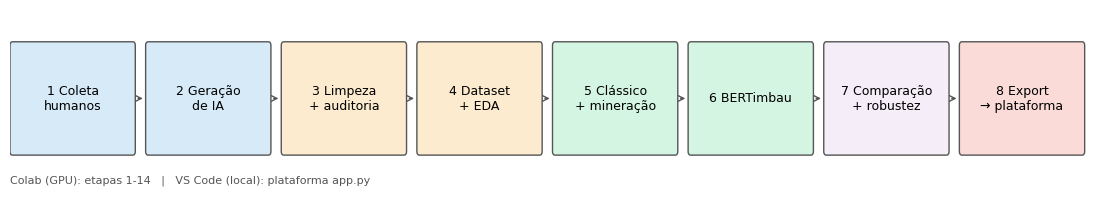

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

etapas = ["1 Coleta\nhumanos", "2 Geração\nde IA", "3 Limpeza\n+ auditoria", "4 Dataset\n+ EDA",
          "5 Clássico\n+ mineração", "6 BERTimbau", "7 Comparação\n+ robustez", "8 Export\n→ plataforma"]
cores = ["#d6eaf8", "#d6eaf8", "#fdebd0", "#fdebd0", "#d5f5e3", "#d5f5e3", "#f5eef8", "#fadbd8"]
fig, ax = plt.subplots(figsize=(14, 2.3)); ax.axis("off"); ax.set_xlim(0, 8.4); ax.set_ylim(0, 1)
for i, (e, c) in enumerate(zip(etapas, cores)):
    ax.add_patch(FancyBboxPatch((i * 1.05 + .02, .2), .93, .6, boxstyle="round,pad=0.02", fc=c, ec="#555"))
    ax.text(i * 1.05 + .485, .5, e, ha="center", va="center", fontsize=9)
    if i < len(etapas) - 1:
        ax.annotate("", xy=((i + 1) * 1.05, .5), xytext=(i * 1.05 + .97, .5), arrowprops=dict(arrowstyle="->", color="#555"))
ax.text(0, .02, "Colab (GPU): etapas 1-14   |   VS Code (local): plataforma app.py", fontsize=8, color="#555")
plt.show()

## Agenda
| Etapa | Conteúdo | Pergunta que responde |
|---|---|---|
| 1 | Ambiente, parâmetros e módulo compartilhado | Como garantir reprodutibilidade? |
| 2 | Coleta dos textos humanos (Wikipedia e portais de notícias `.br`) | De onde vêm os textos humanos? |
| 3 | Geração dos textos de IA (2 modelos abertos, mesmos temas) | Como evitar que o modelo aprenda "assunto"? |
| 4 | **Limpeza e controle de qualidade** (com auditoria) | Quanto do dado bruto sobrevive, e por quê? |
| 5 | Dataset final e análise exploratória | O corpus está balanceado e livre de atalhos? |
| 6 | Divisão treino/validação/teste e métricas | Como avaliar sem vazamento? |
| 7 | Referência ingênua e abordagem clássica (estilometria, TF-IDF de palavras e de caracteres; LR, RF, SVM) | PQ1 |
| 8 | Mineração de dados: padrões de escrita, clustering, visualização | PQ2 |
| 9 | Deep learning: fine-tuning do BERTimbau | PQ1 |
| 10 | Comparação dos modelos | PQ1 |
| 11 | Generalização: outro gerador (inclusive Gemini), outro domínio, texto curto/ruidoso, controles de tamanho de treino | **PQ3** |
| 12 | Análise de erros e interpretabilidade | Onde e por que erramos? |
| 13 | Plataforma (`app.py`) e exportação dos artefatos | Como levar o modelo ao usuário? |
| 14 | Conclusões, limitações e ética | O que concluímos (e o que não)? |

---
# Etapa 1 · Ambiente, parâmetros e módulo compartilhado

**Objetivo:** deixar tudo configurável em um só lugar e criar **um único módulo de texto** (`stylometry.py`) usado no treino **e** na plataforma, para que o texto analisado no app seja tratado exatamente como no treino.

In [ ]:
PINS = {
  "datasets":     "4.8.5",
  "accelerate":   "1.15.0",
  "scipy":        "1.16.3",
  "joblib":       "1.6.0",
  "google-genai": "2.12.1",
}
import subprocess, sys
specs = [f"{p}=={v}" if v else p for p, v in PINS.items()]
r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *specs], capture_output=True, text=True)
print("pip:", "ok" if r.returncode == 0 else r.stderr[-1500:])
print("Pacotes:", ", ".join(specs))
if not all(PINS.values()):
    print("Há pacotes sem versão fixa em PINS: copiem as versões da 1.2b antes da execução final.")

pip: ok
Pacotes: datasets==4.8.5, accelerate==1.15.0, scipy==1.16.3, joblib==1.6.0, google-genai==2.12.1


In [ ]:
import os, re, gc, sys, json, math, random, shutil, time, warnings, unicodedata
from collections import Counter
from datetime import datetime
from urllib.parse import urlparse

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, joblib, sklearn, scipy
from scipy.stats import mannwhitneyu, wilcoxon
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, adjusted_rand_score, normalized_mutual_info_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

import transformers
from transformers import (AutoTokenizer, AutoModel, AutoModelForCausalLM,
                          AutoModelForSequenceClassification, get_linear_schedule_with_warmup)
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")
T0_EXEC = time.time()
plt.rcParams["figure.dpi"] = 110

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "sem GPU: ative em Ambiente de execução > Alterar tipo > GPU")

Dispositivo: cuda | Tesla T4


In [ ]:
import platform
from importlib import metadata
VERSOES = {"python": platform.python_version(),
           **{m.__name__: m.__version__ for m in (np, pd, sklearn, scipy, torch, transformers, joblib)}}
for k, v in VERSOES.items():
    print(f"{k:<13} {v}")

print("\nPara copiar em PINS (1.1):")
for p in PINS:
    try:
        v = metadata.version(p); VERSOES[p] = v; print(f'    "{p}": "{v}",')
    except metadata.PackageNotFoundError:
        print(f'    "{p}": None,   # não instalado')

python        3.13.16
numpy         2.4.6
pandas        2.2.3
sklearn       1.6.1
scipy         1.16.3
torch         2.14.1+cu130
transformers  5.22.1
joblib        1.6.0

Para copiar em PINS (1.1):
    "datasets": "4.8.5",
    "accelerate": "1.15.0",
    "scipy": "1.16.3",
    "joblib": "1.6.0",
    "google-genai": "2.12.1",


### 1.3 Módulo compartilhado `stylometry.py`
Contém o **pré-processamento simétrico** (aplicado igualmente a humanos e IA) e os **atributos estilométricos** (tamanho de frases e palavras, riqueza vocabular, pontuação, stopwords, conectivos, legibilidade Flesch-PT, repetição de n-gramas). A célula grava o arquivo e o importa; na Etapa 13 ele é copiado para a plataforma.

Travessões (`—`, `–`) são convertidos para `-`: LLMs usam muito o travessão tipográfico, e sem essa normalização o classificador poderia aprender um **atalho de formatação** em vez de estilo.

In [ ]:
%%writefile stylometry.py
"""
stylometry.py - pré-processamento e atributos estilométricos para PT-BR.

Projeto: Humano ou IA? Identificação de autoria textual em português (FATEC Jundiaí)
Autores: Allan Vytor Francisco Oliveira, Gabriel Passos, Guilherme Tenório Cavalcante

Este módulo é usado tanto no notebook (treino) quanto na plataforma (app.py).
Manter UM único código garante que o texto analisado no app seja tratado
exatamente como foi tratado no treino.
"""
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd

TRUNC_WORDS = 100
NORMALIZE_TYPOGRAPHY = True

def normalize_ws(t):
    return re.sub(r"\s+", " ", str(t)).strip()

def split_sentences(t):
    return [s for s in re.split(r"(?<=[.!?])\s+", t) if s.strip()]

def n_words(t):
    return len(str(t).split())

def first_n_words(t, n):
    return " ".join(str(t).split()[:n])

def windows(text, size=TRUNC_WORDS, min_last=50):
    """Divide um texto em janelas de `size` palavras (a última só entra se tiver >= min_last)."""
    words = str(text).split()
    if len(words) <= size:
        return [" ".join(words)]
    chunks = [" ".join(words[i:i + size]) for i in range(0, len(words), size)]
    if len(chunks) > 1 and len(chunks[-1].split()) < min_last:
        chunks = chunks[:-1]
    return chunks

_URL_RE = re.compile(r"https?://\S+|www\.\S+")
_EMAIL_RE = re.compile(r"\S+@\S+\.\S+")
_CITE_RE = re.compile(r"\[\s*(\d+|nota \d+|carece de fontes|citation needed)\s*\]", re.I)
_EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF☀-➿\U0001F000-\U0001F2FF]+")
_INVIS_RE = re.compile("[​‌‍﻿­]")
_MD_RE = re.compile(r"[*#`_>]+")
_TYPO = str.maketrans({"“": '"', "”": '"', "‘": "'", "’": "'",
                       "«": '"', "»": '"', "…": "...",
                       "—": "-", "–": "-"})

def preprocess(t):
    """Normaliza Unicode, remove URLs/e-mails/citações/emojis/markdown e padroniza aspas e travessões."""
    t = unicodedata.normalize("NFC", str(t))
    t = _INVIS_RE.sub("", t)
    for rx in (_URL_RE, _EMAIL_RE, _CITE_RE, _EMOJI_RE):
        t = rx.sub(" ", t)
    if NORMALIZE_TYPOGRAPHY:
        t = t.translate(_TYPO)
    t = _MD_RE.sub(" ", t)
    return normalize_ws(t)


STOP_PT = set("a o as os de da do das dos em no na nos nas um uma uns umas e ou mas que se com por para como mais "
              "ao à aos às é são foi ser sua seu suas seus não já também entre sobre até mesmo ela ele eles elas "
              "isso este esta esse essa".split())

CONNECTIVES = ["portanto", "além disso", "entretanto", "no entanto", "contudo", "todavia", "por outro lado",
               "ademais", "dessa forma", "desse modo", "dessa maneira", "assim", "ou seja", "em suma", "por fim",
               "em resumo", "em conclusão", "por exemplo", "porém", "logo", "de fato", "com isso",
               "consequentemente", "sobretudo", "por isso", "em contrapartida"]

EMPHASIS = ["é importante", "é fundamental", "vale destacar", "vale ressaltar", "é essencial",
            "desempenha um papel", "papel fundamental", "papel importante", "diversos aspectos"]

def _phrase_re(items):
    return re.compile(r"\b(" + "|".join(re.escape(x) for x in sorted(items, key=len, reverse=True)) + r")\b")

_CONN_RE = _phrase_re(CONNECTIVES)
_EMPH_RE = _phrase_re(EMPHASIS)

_VOW_GROUP = re.compile(r"[aeiouáéíóúâêôãõàü]+")
_STRONG = re.compile(r"[aeoáéóâêôãõ]")

def count_syllables_pt(word):
    """Aproximação: cada grupo vocálico = 1 sílaba; vogais fortes consecutivas (a/e/o) formam hiato."""
    n = 0
    for g in _VOW_GROUP.findall(word.lower()):
        n += max(1, len(_STRONG.findall(g)))
    return max(n, 1)

def flesch_pt(n_words_, n_sents, n_syll):
    """Índice de Facilidade de Leitura Flesch adaptado ao português (Martins et al., 1996)."""
    if n_words_ == 0 or n_sents == 0:
        return 0.0
    return 248.835 - 1.015 * (n_words_ / n_sents) - 84.6 * (n_syll / n_words_)

def stylo_features(t):
    t = str(t)
    words = re.findall(r"\w+", t.lower())
    nw = max(len(words), 1)
    sents = split_sentences(t) or [t]
    sl = np.array([len(re.findall(r"\w+", s)) for s in sents], dtype=float)
    bi = list(zip(words, words[1:]))
    tri = list(zip(words, words[1:], words[2:]))
    cnt = Counter(words)
    syl = sum(count_syllables_pt(w) for w in words)
    low = t.lower()
    L = max(len(t), 1)
    return {
        "st_n_sents": len(sents),
        "st_avg_sent_len": sl.mean(),
        "st_std_sent_len": sl.std(),
        "st_cv_sent_len": sl.std() / (sl.mean() + 1e-9),
        "st_max_sent_len": sl.max(),
        "st_avg_word_len": float(np.mean([len(w) for w in words])) if words else 0.0,
        "st_long_word_ratio": float(np.mean([len(w) >= 9 for w in words])) if words else 0.0,
        "st_ttr": len(cnt) / nw,
        "st_hapax_ratio": sum(1 for c in cnt.values() if c == 1) / nw,
        "st_stop_ratio": sum(w in STOP_PT for w in words) / nw,
        "st_connectives": 100 * len(_CONN_RE.findall(low)) / nw,
        "st_emphasis": 100 * len(_EMPH_RE.findall(low)) / nw,
        "st_flesch": flesch_pt(len(words), len(sents), syl),
        "st_syll_per_word": syl / nw,
        "st_comma": t.count(",") / nw,
        "st_period": t.count(".") / nw,
        "st_colon_semicolon": (t.count(":") + t.count(";")) / nw,
        "st_excl_quest": (t.count("!") + t.count("?")) / nw,
        "st_quotes_parens": sum(t.count(c) for c in '"()') / nw,
        "st_dash": t.count(" - ") / nw,
        "st_digit_ratio": sum(c.isdigit() for c in t) / L,
        "st_upper_ratio": sum(c.isupper() for c in t) / L,
        "st_rep_bigram": 1 - len(set(bi)) / max(len(bi), 1),
        "st_rep_trigram": 1 - len(set(tri)) / max(len(tri), 1),
    }

FEATURE_COLS = list(stylo_features("Exemplo de texto. Outra frase aqui, com vírgula.").keys())

FEATURE_LABELS = {
    "st_n_sents": "Nº de frases",
    "st_avg_sent_len": "Tamanho médio da frase (palavras)",
    "st_std_sent_len": "Desvio do tamanho das frases",
    "st_cv_sent_len": "Variação relativa do tamanho das frases",
    "st_max_sent_len": "Maior frase (palavras)",
    "st_avg_word_len": "Tamanho médio da palavra (letras)",
    "st_long_word_ratio": "Proporção de palavras longas (>=9 letras)",
    "st_ttr": "Riqueza vocabular (type-token ratio)",
    "st_hapax_ratio": "Palavras que aparecem uma só vez",
    "st_stop_ratio": "Proporção de stopwords",
    "st_connectives": "Conectivos (por 100 palavras)",
    "st_emphasis": "Marcadores de ênfase (por 100 palavras)",
    "st_flesch": "Legibilidade (Flesch-PT; maior = mais fácil)",
    "st_syll_per_word": "Sílabas por palavra (aprox.)",
    "st_comma": "Vírgulas por palavra",
    "st_period": "Pontos por palavra",
    "st_colon_semicolon": "Dois-pontos e ponto e vírgula por palavra",
    "st_excl_quest": "Exclamações e interrogações por palavra",
    "st_quotes_parens": "Aspas e parênteses por palavra",
    "st_dash": "Travessões ( - ) por palavra",
    "st_digit_ratio": "Proporção de dígitos",
    "st_upper_ratio": "Proporção de maiúsculas",
    "st_rep_bigram": "Repetição de bigramas",
    "st_rep_trigram": "Repetição de trigramas",
}

def build_features(texts):
    """DataFrame (uma linha por texto) com os atributos estilométricos, na ordem de FEATURE_COLS."""
    return pd.DataFrame([stylo_features(t) for t in texts])[FEATURE_COLS]

Writing stylometry.py


In [ ]:
sys.path.insert(0, os.getcwd())
import importlib, stylometry
importlib.reload(stylometry)
from stylometry import (TRUNC_WORDS, normalize_ws, split_sentences, n_words, first_n_words, windows, preprocess,
                        STOP_PT, CONNECTIVES, FEATURE_COLS, FEATURE_LABELS, build_features, stylo_features)
print(f"Atributos estilométricos: {len(FEATURE_COLS)} | tamanho-alvo dos textos: {TRUNC_WORDS} palavras")

Atributos estilométricos: 24 | tamanho-alvo dos textos: 100 palavras


### 1.4 Parâmetros do experimento

In [ ]:
QUICK_MODE   = False
N_PER_DOMAIN = 40 if QUICK_MODE else 300
OVERSAMPLE   = 1.15
RAW_WORDS    = 300
MIN_WORDS    = TRUNC_WORDS
MAX_NEW_TOKENS, GEN_BATCH = 320, 16
DOMAINS      = ("wiki", "noticias")
NEWS_SCAN_LIMIT = 300_000 if QUICK_MODE else 2_000_000

GENERATORS = {"qwen": "Qwen/Qwen2.5-1.5B-Instruct", "phi": "microsoft/Phi-3.5-mini-instruct"}

RUN_EXTERNAL = True
GEMINI_MODELS = ["gemini-3.1-flash-lite",
                 "gemini-3.5-flash-lite",
                 "gemini-3.6-flash",
                 "gemini-3.5-flash"]
GEMINI_MODEL = GEMINI_MODELS[0]
GEMINI_SECRET_NAMES = ["GEMINI_API_KEY",
                       "GEMINI_API_KEY_2",
                       "GEMINI_API_KEY_3",
                       "GEMINI_API_KEY_4",
                       "GEMINI_API_KEY_5"]

FILTROS_APOS_CORTE = True

BERT_MODEL = "neuralmind/bert-base-portuguese-cased"
BERT_MAX_LEN = 192

USE_DRIVE = True
PROJ_NOME = "auditoria_humano_ia_final"
PROJ_ANTERIOR = "autoria_humano_vs_ia"
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJ = f"/content/drive/MyDrive/{PROJ_NOME}"
else:
    PROJ = f"/content/{PROJ_NOME}"
for sub in ["data", "figs", "export"]:
    os.makedirs(os.path.join(PROJ, sub), exist_ok=True)

RAW_PATH = os.path.join(PROJ, "data", f"dataset_bruto_n{N_PER_DOMAIN}.csv")
if USE_DRIVE and not os.path.exists(RAW_PATH):
    old_data = os.path.join("/content/drive/MyDrive", PROJ_ANTERIOR, "data")
    for f in [f"dataset_bruto_n{N_PER_DOMAIN}.csv"] + [f"geracao_{k}_n{N_PER_DOMAIN}.csv" for k in ("qwen", "phi")]:
        if os.path.exists(os.path.join(old_data, f)):
            shutil.copy(os.path.join(old_data, f), os.path.join(PROJ, "data", f)); print("Copiado da pasta anterior:", f)
LOAD_RAW = os.path.exists(RAW_PATH)
print("Projeto em:", PROJ, "| dataset bruto já existe?", LOAD_RAW)

def savefig(name):
    plt.savefig(os.path.join(PROJ, "figs", f"{name}.png"), dpi=200, bbox_inches="tight")

Mounted at /content/drive
Projeto em: /content/drive/MyDrive/auditoria_humano_ia_final | dataset bruto já existe? True


In [ ]:
def _ler_secret(nome):
    try:
        from google.colab import userdata
        return userdata.get(nome)
    except Exception:
        return os.environ.get(nome)

def get_gemini_keys():
    """[(nome do Secret, chave)] na ordem de GEMINI_SECRET_NAMES, só com as chaves preenchidas e sem repetição."""
    out, vistas = [], set()
    for nome in GEMINI_SECRET_NAMES:
        k = _ler_secret(nome)
        if k and k not in vistas:
            out.append((nome, k)); vistas.add(k)
    return out

if RUN_EXTERNAL:
    chaves = get_gemini_keys(); usadas = {n for n, _ in chaves}
    print(f"Chaves do Gemini utilizáveis: {len(chaves)} de {len(GEMINI_SECRET_NAMES)} | modelo: {GEMINI_MODEL}")
    for nome in GEMINI_SECRET_NAMES:
        st = "ok" if nome in usadas else ("repetida (mesma chave de outro Secret)" if _ler_secret(nome) else "não encontrada")
        print(f"  {nome:<18} {st}")
    if not chaves:
        print("Nenhuma chave: a 11.4 vai ser pulada. Configurem no Colab: ícone de chave > Adicionar > "
              "nome GEMINI_API_KEY > colar a chave > ativar o acesso do notebook.")

Chaves do Gemini utilizáveis: 5 de 5 | modelo: gemini-3.1-flash-lite
  GEMINI_API_KEY     ok
  GEMINI_API_KEY_2   ok
  GEMINI_API_KEY_3   ok
  GEMINI_API_KEY_4   ok
  GEMINI_API_KEY_5   ok


---
# Etapa 2 · Coleta dos textos humanos

**Objetivo:** reunir textos escritos por pessoas, em português, de duas fontes públicas.

| Fonte | Papel | Gênero |
|---|---|---|
| **Wikipedia PT** (`wikimedia/wikipedia`) | fonte principal | enciclopédico |
| **Notícias brasileiras** (FineWeb-2, filtrado por portais jornalísticos) | segundo domínio, usado também para testar generalização | jornalístico |

Guardamos o texto **bruto** (até 300 palavras) e o **tema** de cada documento. A limpeza pesada acontece na Etapa 4, de forma auditável.

### 2.0 Acesso aos dados, licença e privacidade

**Fontes**
- **Wikipedia em português:** `wikimedia/wikipedia`, dump `20231101.pt`, licença CC BY-SA 4.0. Reutilizar trechos exige atribuição e a mesma licença.
- **Notícias:** páginas de portais brasileiros obtidas do FineWeb-2 (`HuggingFaceFW/fineweb-2`, subconjunto `por_Latn`). O FineWeb-2 é distribuído sob ODC-By, mas o texto de cada notícia continua pertencendo ao portal que a publicou.
- **Textos de IA:** gerados neste notebook pelo Qwen2.5-1.5B e pelo Phi-3.5-mini e, só para o teste, pelo Gemini via API.

**Como o notebook obtém os dados**
- Se `data/dataset_bruto_n300.csv` existe na pasta do projeto no Drive, o notebook lê esse arquivo e pula a coleta e a geração (Etapas 2 e 3).
- Sem o arquivo, o notebook recoleta os textos humanos e regera os de IA. Isso exige GPU e leva tempo (só a geração, nas células 3.3 e 3.4, estima 15 a 30 minutos). Os textos de IA saem diferentes dos da execução registrada, porque a geração usa amostragem (`temperature=0.8`).
- Os textos do Gemini ficam em `data/geracao_gemini_v4_n300.csv`. Com esse arquivo presente, a 11.4 só gera os temas que ainda faltam.

**Acesso para avaliação**
- Os CSVs estão numa pasta do Drive compartilhada só com o professor: [pasta do projeto no Drive](https://drive.google.com/drive/folders/17udv22OHqUHohWC3zIJPh2iXhrnsIRNj?usp=sharing). Para rodar, copiem a pasta para `MyDrive/auditoria_humano_ia_final/` ou ajustem `PROJ` na 1.4.
- Os CSVs não vão para repositório público: contêm o texto integral de notícias de terceiros.
- O pacote da plataforma (13.2) não leva o `dataset_limpo.csv`, porque o `app.py` não usa esse arquivo.
- Nenhuma credencial aparece no código: a chave do Gemini fica nos Secrets do Colab.

**Privacidade.** Os textos são públicos e não houve coleta de dados de usuários. Verbetes biográficos e notícias citam pessoas reais, então os CSVs circulam só entre o grupo e o professor.

In [ ]:
from datasets import load_dataset

def collect_wikipedia(n):
    ds = load_dataset("wikimedia/wikipedia", "20231101.pt", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10_000)
    out, seen, pbar = [], set(), tqdm(total=n, desc="Wikipedia")
    for ex in ds:
        title, tl = ex["title"], ex["title"].lower()
        if "desambigu" in tl or tl.startswith(("lista de", "anexo", "categoria")):
            continue
        lines = [l.strip() for l in ex["text"].split("\n") if n_words(l) >= 12]
        body = normalize_ws(" ".join(lines))
        if n_words(body) < MIN_WORDS or body[:60] in seen:
            continue
        seen.add(body[:60])
        out.append({"domain": "wiki", "topic": title, "raw_text": first_n_words(body, RAW_WORDS)})
        pbar.update(1)
        if len(out) >= n: break
    pbar.close(); return out

N_COLLECT = int(N_PER_DOMAIN * OVERSAMPLE)
wiki_rows = [] if LOAD_RAW else collect_wikipedia(N_COLLECT)
print(len(wiki_rows), "textos da Wikipedia coletados")

0 textos da Wikipedia coletados


In [ ]:
NEWS_DOMAINS = [
    "g1.globo.com", "oglobo.globo.com", "valor.globo.com", "folha.uol.com.br", "noticias.uol.com.br",
    "economia.uol.com.br", "estadao.com.br", "cnnbrasil.com.br", "agenciabrasil.ebc.com.br", "r7.com",
    "terra.com.br", "metropoles.com", "correiobraziliense.com.br", "gazetadopovo.com.br", "em.com.br",
    "otempo.com.br", "gauchazh.clicrbs.com.br", "band.uol.com.br", "poder360.com.br", "exame.com",
    "veja.abril.com.br", "istoe.com.br", "cartacapital.com.br", "infomoney.com.br", "opovo.com.br",
    "diariodepernambuco.com.br", "jc.ne10.uol.com.br", "atarde.com.br", "correio24horas.com.br",
    "acritica.com", "nsctotal.com.br", "jornaldebrasilia.com.br", "diariodonordeste.verdesmares.com.br",
    "odia.ig.com.br", "extra.globo.com", "jornaldocomercio.com", "tribunaonline.com.br", "campograndenews.com.br",
]
_NEWS_PATH = re.compile(r"/noticias?(/|-|\.)|/news/|/ultimas-noticias")

def is_news(url):
    u = urlparse(url or ""); host = u.netloc.lower().removeprefix("www.")
    if any(host == d or host.endswith("." + d) for d in NEWS_DOMAINS):
        return True
    return host.endswith(".br") and bool(_NEWS_PATH.search(u.path.lower()))

def collect_news(n, scan_limit=NEWS_SCAN_LIMIT):
    ds = load_dataset("HuggingFaceFW/fineweb-2", name="por_Latn", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=10_000)
    out, seen, pbar = [], set(), tqdm(total=n, desc="Notícias .br")
    for i, ex in enumerate(ds):
        if i >= scan_limit or len(out) >= n: break
        if not is_news(ex.get("url", "")): continue
        paras = [normalize_ws(p) for p in ex["text"].split("\n") if n_words(p) >= 8]
        sents = split_sentences(" ".join(paras))
        if len(sents) < 4: continue
        topic, rest = sents[0], " ".join(sents[1:])
        if not (4 <= n_words(topic) <= 35) or n_words(rest) < MIN_WORDS or rest[:60] in seen: continue
        seen.add(rest[:60])
        out.append({"domain": "noticias", "topic": topic, "raw_text": first_n_words(rest, RAW_WORDS), "url": ex.get("url", "")})
        pbar.update(1)
    pbar.close()
    if len(out) < n:
        print(f"Só {len(out)} notícias em {scan_limit:,} documentos. Aumente NEWS_SCAN_LIMIT se quiser mais "
              f"(o corpus continua balanceado: cada notícia tem o seu par de IA).")
    return out

news_rows = [] if LOAD_RAW else collect_news(N_COLLECT)
print(len(news_rows), "notícias coletadas")
if news_rows:
    print("Portais mais frequentes:", Counter(urlparse(r["url"]).netloc for r in news_rows).most_common(8))
if not LOAD_RAW:
    assert wiki_rows and news_rows, "Falha na coleta: verifique a conexão e os nomes dos datasets."

0 notícias coletadas


---
# Etapa 3 · Geração dos textos de IA

**Objetivo:** para **cada texto humano** gerar **um** texto de IA **sobre o mesmo tema e no mesmo gênero**. Assim o classificador não consegue "trapacear" aprendendo assunto, e o corpus nasce **pareado** (1 humano ↔ 1 IA).

- Dois geradores de famílias diferentes (**Qwen2.5-1.5B** e **Phi-3.5-mini**), alternados: cada um escreve metade dos textos de cada domínio. Isso permite a pergunta central da PQ3: *treinar com um, testar no outro*.
- Prompt padronizado por domínio (verbete de enciclopédia ou notícia), pedindo texto corrido, ~150 palavras, sem título/markdown. Amostragem com `temperature=0.8`.
- Um terceiro gerador, comercial e bem maior (**Gemini**), é usado **apenas no teste** (Etapa 11.4).

In [ ]:
PROMPT_TEMPLATES = {
    "wiki": 'Escreva o início de um verbete de enciclopédia, em português, sobre o tema: "{topic}". '
            'Escreva cerca de 150 palavras, em um único parágrafo, sem título, sem listas e sem '
            'formatação markdown. Responda apenas com o texto.',
    "noticias": 'Escreva uma notícia jornalística em português do Brasil a partir da seguinte manchete ou lide: "{topic}". '
                'Escreva cerca de 150 palavras, em texto corrido, sem título, sem listas e sem '
                'formatação markdown. Responda apenas com o texto da notícia.',
}
SYSTEM_PROMPT = "Você é um assistente prestativo que escreve em português do Brasil."

if not LOAD_RAW:
    humans = pd.DataFrame(wiki_rows + news_rows).drop(columns="url", errors="ignore").reset_index(drop=True)
    humans["topic_id"] = humans.index
    humans["group"] = humans.domain + "_" + humans.topic_id.astype(str)
    humans["generator"] = np.where(humans.groupby("domain").cumcount() % 2 == 0, "qwen", "phi")
    print(humans.groupby(["domain", "generator"]).size().unstack())

In [ ]:
def load_generator(name):
    tok = AutoTokenizer.from_pretrained(name, padding_side="left")
    if tok.pad_token is None: tok.pad_token = tok.eos_token
    model = AutoModelForCausalLM.from_pretrained(
        name, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32).to(DEVICE).eval()
    return tok, model

@torch.no_grad()
def generate_texts(tok, model, prompts, max_new_tokens=MAX_NEW_TOKENS, batch=GEN_BATCH, temperature=0.8, top_p=0.95):
    outs = []
    for i in tqdm(range(0, len(prompts), batch), desc="Gerando"):
        chats = [tok.apply_chat_template([{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": p}],
                                         tokenize=False, add_generation_prompt=True) for p in prompts[i:i + batch]]
        enc = tok(chats, return_tensors="pt", padding=True).to(DEVICE)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=True, temperature=temperature,
                             top_p=top_p, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return outs

def run_generator(key):
    path = os.path.join(PROJ, "data", f"geracao_{key}_n{N_PER_DOMAIN}.csv")
    if os.path.exists(path): return pd.read_csv(path)
    sub = humans[humans.generator == key]
    prompts = [PROMPT_TEMPLATES[d].format(topic=t.replace('"', "'")) for d, t in zip(sub.domain, sub.topic)]
    tok, model = load_generator(GENERATORS[key])
    outs = generate_texts(tok, model, prompts)
    del model, tok; gc.collect(); torch.cuda.empty_cache()
    res = pd.DataFrame({"topic_id": sub.topic_id.values, "raw_text": outs, "generator": key})
    res.to_csv(path, index=False); return res

In [ ]:
ai_qwen = None if LOAD_RAW else run_generator("qwen")
if ai_qwen is not None: print(ai_qwen.raw_text.iloc[0][:600])

In [ ]:
ai_phi = None if LOAD_RAW else run_generator("phi")
if ai_phi is not None: print(ai_phi.raw_text.iloc[0][:600])

In [ ]:
if LOAD_RAW:
    df_raw = pd.read_csv(RAW_PATH)
else:
    ai = pd.concat([ai_qwen, ai_phi], ignore_index=True)
    ai = ai.merge(humans[["topic_id", "topic", "group", "domain"]], on="topic_id", how="left")
    ai["source"], ai["label"] = ai.generator, 1
    h = humans.assign(source="human", label=0)
    cols = ["group", "domain", "topic_id", "topic", "source", "label", "raw_text"]
    df_raw = pd.concat([h[cols], ai[cols]], ignore_index=True)
    df_raw.to_csv(RAW_PATH, index=False)
print("Dataset BRUTO:", df_raw.shape, "->", RAW_PATH)
display(df_raw.groupby(["domain", "source"]).size().unstack(fill_value=0))

Dataset BRUTO: (1380, 7) -> /content/drive/MyDrive/auditoria_humano_ia_final/data/dataset_bruto_n300.csv


source,human,phi,qwen
domain,,,
noticias,345,172,173
wiki,345,172,173


---
# Etapa 4 · Limpeza e controle de qualidade

**Objetivo:** transformar o dado bruto em um corpus **limpo, comparável e balanceado**, registrando **o que foi removido e por quê**.

**Princípios**
1. **Limpeza simétrica:** a mesma normalização é aplicada a humanos e IA (URLs, e-mails, citações `[1]`, emojis, markdown, aspas e travessões tipográficos). Se só limpássemos um lado, o modelo aprenderia a limpeza, não a autoria.
2. **Tratamento específico só do que é artefato de LLM:** preâmbulos ("Claro! Aqui está…") e títulos.
3. **Filtros de qualidade** com motivo registrado: curto demais, idioma/alfabeto errado, "meta-texto" de LLM (recusas, "como modelo de linguagem…"), caracteres anormais, repetição degenerada, duplicatas.
   Com `FILTROS_APOS_CORTE = True` (1.4), os filtros de idioma, caracteres e repetição olham só as 100 palavras que entram no corpus (ver 4.5b).
4. **Corte em exatamente 100 palavras** (controla o tamanho) e **pares completos** (se um lado do par cai, o outro cai também → corpus balanceado por construção).

In [ ]:
def strip_llm_preamble(t):
    t = re.sub(r"^(claro|certo|com certeza|aqui est[áa]|segue)\b[^\n]{0,80}?[:!]\s*", "", str(t).strip(), flags=re.I)
    lines = [l.strip() for l in t.split("\n") if l.strip()]
    for _ in range(2):
        if len(lines) > 1 and n_words(lines[0]) < 8 and not lines[0].endswith((".", "!", "?")):
            lines = lines[1:]
    return "\n".join(lines)

CJK_RE = re.compile(r"[Ѐ-ӿ֐-ۿ぀-ヿ㐀-鿿가-힯]")
META_RE = re.compile(r"(como (um|uma) (modelo|assistente|ia|inteligência artificial)|não posso (ajudar|fornecer|escrever|criar|atender)"
                     r"|desculpe|sinto muito|word count|contagem de palavras|\bnota:|\bobservação:|\(\d+ palavras\))", re.I)

def f_curto(t):   return n_words(t) < MIN_WORDS
def f_idioma(t):
    ws = re.findall(r"\w+", t.lower())
    return bool(CJK_RE.search(t)) or (sum(w in STOP_PT for w in ws) / max(len(ws), 1) < 0.20)
def f_meta(t):    return bool(META_RE.search(t))
def f_chars(t):
    cs = [c for c in t if not c.isspace()]; n = max(len(cs), 1)
    return (sum(c.isalpha() for c in cs) / n < 0.85) or (sum(c.isdigit() for c in cs) / n > 0.10)
def f_repeticao(t):
    w = t.lower().split(); tri = Counter(zip(w, w[1:], w[2:]))
    return (len(set(w)) / max(len(w), 1) < 0.30) or bool(tri and max(tri.values()) >= 4)

def no_corte(f):
    return lambda t: f(first_n_words(t, TRUNC_WORDS))

_tam = no_corte if FILTROS_APOS_CORTE else (lambda f: f)
FILTERS = [("curto_demais", f_curto), ("idioma_ou_alfabeto", _tam(f_idioma)), ("meta_llm_ou_recusa", f_meta),
           ("caracteres_anormais", _tam(f_chars)), ("repeticao_degenerada", _tam(f_repeticao))]
print("Filtros de idioma, caracteres e repetição aplicados", f"às primeiras {TRUNC_WORDS} palavras" if FILTROS_APOS_CORTE else "ao texto inteiro")

def shingles(t, k=5):
    w = t.lower().split(); return {" ".join(w[i:i + k]) for i in range(max(len(w) - k + 1, 1))}
def find_near_dups(texts, thr=0.8):
    sh, dup = [shingles(t) for t in texts], set()
    for i in range(len(sh)):
        if i in dup: continue
        for j in range(i + 1, len(sh)):
            if j not in dup and sh[i] & sh[j] and len(sh[i] & sh[j]) / len(sh[i] | sh[j]) >= thr:
                dup.add(j)
    return dup

Filtros de idioma, caracteres e repetição aplicados às primeiras 100 palavras


In [ ]:
def apply_filters(d):
    d["drop_reason"] = None
    for nome, fn in FILTERS:
        pend = d.drop_reason.isna()
        hit = d.loc[pend, "text"].map(fn)
        d.loc[hit[hit].index, "drop_reason"] = nome
    return d

def clean_dataframe(raw):
    d = raw.copy().reset_index(drop=True)
    d["text"] = d.raw_text.fillna("").astype(str)
    ia = d.label == 1
    d.loc[ia, "text"] = d.loc[ia, "text"].map(strip_llm_preamble)
    d["text"] = d.text.map(preprocess)
    d = apply_filters(d)
    ok = d.drop_reason.isna()
    d.loc[ok, "text"] = d.loc[ok, "text"].map(lambda t: first_n_words(t, TRUNC_WORDS))
    for lab in (0, 1):
        idx = d[d.drop_reason.isna() & (d.label == lab)].index
        dup = find_near_dups(d.loc[idx, "text"].tolist())
        d.loc[[idx[i] for i in dup], "drop_reason"] = "duplicata"
    vivos = d[d.drop_reason.isna()].groupby("group").label.nunique()
    quebrados = vivos[vivos < 2].index
    d.loc[d.drop_reason.isna() & d.group.isin(quebrados), "drop_reason"] = "par_incompleto"
    return d

d_clean = clean_dataframe(df_raw)
ORDEM = ["curto_demais", "idioma_ou_alfabeto", "meta_llm_ou_recusa", "caracteres_anormais",
         "repeticao_degenerada", "duplicata", "par_incompleto"]
print("Linhas brutas:", len(d_clean), "| mantidas:", d_clean.drop_reason.isna().sum())

Linhas brutas: 1380 | mantidas: 1198


### 4.5 Auditoria da limpeza
O funil abaixo mostra quantos textos sobraram após cada filtro, por classe. Assim quem avalia o trabalho vê o que foi descartado e por quê.

classe,IA,humano
motivo,,
curto_demais,52,0
idioma_ou_alfabeto,4,15
meta_llm_ou_recusa,18,1
caracteres_anormais,0,5
repeticao_degenerada,0,2
duplicata,0,0
par_incompleto,17,68
MANTIDO,599,599


,humano,IA
etapa,,
bruto,690,690
após 'curto_demais',690,638
após 'idioma_ou_alfabeto',675,634
após 'meta_llm_ou_recusa',674,616
após 'caracteres_anormais',669,616
após 'repeticao_degenerada',667,616
após 'duplicata',667,616
após 'par_incompleto',599,599


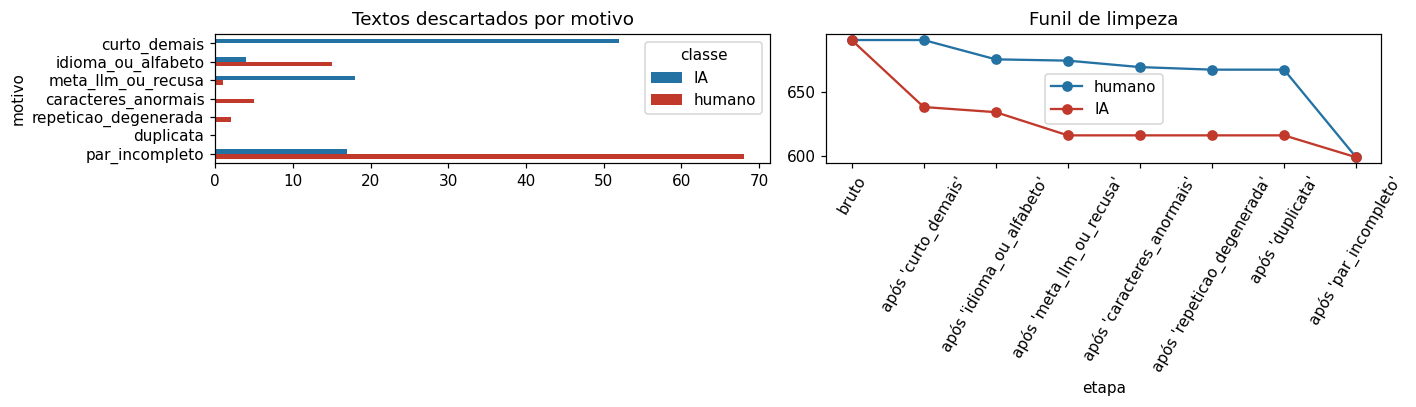

**Resumo:** foram descartados **13.2%** dos textos humanos e **13.2%** dos de IA (o descarte inclui os pares que perderam a outra metade). O motivo mais frequente foi **`par_incompleto`**.

In [ ]:
d_clean["classe"] = np.where(d_clean.label == 0, "humano", "IA")
motivos = d_clean.assign(motivo=d_clean.drop_reason.fillna("MANTIDO")).groupby(["motivo", "classe"]).size().unstack(fill_value=0)
motivos = motivos.reindex(ORDEM + ["MANTIDO"]).fillna(0).astype(int)
display(motivos)

funil = [{"etapa": "bruto", "humano": (d_clean.label == 0).sum(), "IA": (d_clean.label == 1).sum()}]
rest = d_clean.copy()
for m in ORDEM:
    rest = rest[rest.drop_reason != m]
    funil.append({"etapa": f"após '{m}'", "humano": (rest.label == 0).sum(), "IA": (rest.label == 1).sum()})
funil = pd.DataFrame(funil).set_index("etapa"); display(funil)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
motivos.drop("MANTIDO").plot.barh(ax=ax[0], color=["#2471a3", "#c0392b"]); ax[0].set_title("Textos descartados por motivo"); ax[0].invert_yaxis()
funil.plot(ax=ax[1], marker="o", color=["#2471a3", "#c0392b"]); ax[1].set_title("Funil de limpeza"); ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); savefig("limpeza_auditoria"); plt.show()

taxa = (1 - motivos.loc["MANTIDO"] / motivos.sum()).round(3)
display(Markdown(f"**Resumo:** foram descartados **{taxa['humano']:.1%}** dos textos humanos e **{taxa['IA']:.1%}** dos de IA "
                 f"(o descarte inclui os pares que perderam a outra metade). O motivo mais frequente foi "
                 f"**`{motivos.drop('MANTIDO').sum(axis=1).idxmax()}`**."))

### 4.5b Diagnóstico: o filtro de repetição descarta mais humanos?
Na execução da V1, `repeticao_degenerada` descartou 46 textos humanos e 3 de IA. Os filtros rodavam no texto inteiro, antes do corte em 100 palavras. O texto humano bruto vai até 300 palavras e o de IA fica perto de 150, e um trigrama repetido 4 vezes é mais provável num texto longo. Então o filtro podia estar descartando textos humanos normais, o que seria viés de seleção.

A célula abaixo não altera o dataset. Ela mostra:
1. o tamanho dos textos antes do corte, por classe;
2. quantos textos o filtro descartaria olhando o texto inteiro e olhando só as 100 palavras do corpus;
3. dez textos humanos descartados, com o trigrama mais repetido de cada um.

**Decisão do grupo:** a maioria dos humanos descartados era texto normal, então a execução final usa `FILTROS_APOS_CORTE = True` (1.4): os filtros de idioma, caracteres e repetição olham só as 100 palavras que entram no corpus. Nesta execução, olhando o texto inteiro, o filtro de repetição descartaria 39 textos humanos e 3 de IA; olhando só as 100 palavras, 2 humanos e nenhum de IA.

In [ ]:
diag = d_clean[["label", "classe", "raw_text"]].copy()
txt_full = diag.raw_text.fillna("").astype(str)
eh_ia = diag.label == 1
txt_full[eh_ia] = txt_full[eh_ia].map(strip_llm_preamble)
txt_full = txt_full.map(preprocess)
diag["palavras"] = txt_full.map(n_words)
diag = diag[diag.palavras >= TRUNC_WORDS]
diag["rep_texto_inteiro"] = txt_full[diag.index].map(f_repeticao)
diag["rep_so_corpus"] = txt_full[diag.index].map(no_corte(f_repeticao))

print("Palavras antes do corte, por classe:")
display(diag.groupby("classe").palavras.describe()[["mean", "50%", "max"]].round(0))
print(f"Textos que o filtro de repetição descartaria (aplicado sozinho a todos os textos com {TRUNC_WORDS}+ palavras):")
display(diag.groupby("classe")[["rep_texto_inteiro", "rep_so_corpus"]].sum()
        .rename(columns={"rep_texto_inteiro": "olhando o texto inteiro", "rep_so_corpus": f"olhando só as {TRUNC_WORDS} palavras"}))

desc = diag[diag.rep_texto_inteiro & (diag.label == 0)]
print(f"\n{len(desc)} humanos descartados olhando o texto inteiro; "
      f"{int((~desc.rep_so_corpus).sum())} deles passariam se o filtro olhasse só as {TRUNC_WORDS} palavras.\n")
for t in txt_full[desc.index].head(10):
    w = t.lower().split(); (tri, n_rep), = Counter(zip(w, w[1:], w[2:])).most_common(1)
    print(f"[trigrama mais repetido: '{' '.join(tri)}' x{n_rep} | {len(w)} palavras]\n{t[:400]}\n---")

Palavras antes do corte, por classe:


,mean,50%,max
classe,,,
IA,160.0,165.0,209.0
humano,236.0,274.0,300.0


Textos que o filtro de repetição descartaria (aplicado sozinho a todos os textos com 100+ palavras):


,olhando o texto inteiro,olhando só as 100 palavras
classe,,
IA,3,0
humano,39,2



39 humanos descartados olhando o texto inteiro; 37 deles passariam se o filtro olhasse só as 100 palavras.

[trigrama mais repetido: 'the temperance seven' x4 | 272 palavras]
The Temperance Seven é uma banda britânica de jazz formada no final dos anos 50 por Paul McDowell (trombone), Philip Harrison (banjo) e Brian Innes. O grupo eventualmente evoluiu para uma formação de nove integrantes, especializando-se em um estilo leve e bem humorado que evocava a música das décadas de 1920 e 1930. Obteve grande êxito nos anos 60 com singles como "You're Driving Me Crazy" (que ch
---
[trigrama mais repetido: 'caminhos de ferro' x5 | 300 palavras]
A Estação Ferroviária de Cabeço de Vide-Vaiamonte, originalmente denominada de Cabeço de Vide, é uma interface encerrada do Ramal de Portalegre, que servia a localidade de Cabeço de Vide, no concelho de Fronteira, em Portugal. Entrou ao serviço em 20 de Janeiro de 1937. Em 1898, quando se realizaram os estudos para a elaboração do Plano da Rede ao Sul d

In [ ]:
amostra = d_clean[(d_clean.label == 1)].head(3)
for _, r in amostra.iterrows():
    print(f"--- [{r.source}/{r.domain}] BRUTO:\n{str(r.raw_text)[:350]}\n--- LIMPO ({r.drop_reason or 'mantido'}):\n{r.text[:350]}\n")

--- [qwen/wiki] BRUTO:
O Centro Desportivo Universitário de Lisboa (CDU) é uma instituição importante para a comunidade esportiva da capital portuguesa. Localizado no centro histórico de Lisboa, próximo à Praça do Comércio, o CDU serve como ponto de encontro e apoio para diversos atletas universitários, oferecendo equipamentos e infraestrutura para prática desportiva int
--- LIMPO (mantido):
O Centro Desportivo Universitário de Lisboa (CDU) é uma instituição importante para a comunidade esportiva da capital portuguesa. Localizado no centro histórico de Lisboa, próximo à Praça do Comércio, o CDU serve como ponto de encontro e apoio para diversos atletas universitários, oferecendo equipamentos e infraestrutura para prática desportiva int

--- [qwen/wiki] BRUTO:
Friedrich Spee (28 de setembro de 1637 - 14 de agosto de 1695) foi um importante teólogo protestante alemão do século XVII. Autor dos Textos Elementares da Bíblia Cristã, ele também se destacou como filósofo e comentarista bíblico

In [ ]:
df = d_clean[d_clean.drop_reason.isna()][["group", "domain", "topic_id", "topic", "source", "label", "text"]].reset_index(drop=True)

assert df.text.map(n_words).eq(TRUNC_WORDS).all(), "todos os textos devem ter exatamente TRUNC_WORDS palavras"
assert df.label.value_counts().nunique() == 1, "classes desbalanceadas"
assert df.groupby("group").label.nunique().eq(2).all(), "há par incompleto"
print(f"Integridade OK: {len(df)} textos = {len(df)//2} pares | {TRUNC_WORDS} palavras cada | classes balanceadas")

CLEAN_PATH = os.path.join(PROJ, "data", "dataset_limpo.csv")
df.to_csv(CLEAN_PATH, index=False)
card = {"nome": "Autoria humano vs IA (PT-BR)", "criado_em": datetime.now().isoformat(timespec="seconds"),
        "autores": ["Allan Vytor Francisco Oliveira", "Gabriel Passos", "Guilherme Tenório Cavalcante"],
        "fontes_humanas": {"wiki": "wikimedia/wikipedia 20231101.pt",
                           "noticias": "HuggingFaceFW/fineweb-2 por_Latn (portais de notícias brasileiros)"},
        "geradores": GENERATORS, "parametros": {"N_PER_DOMAIN": N_PER_DOMAIN, "TRUNC_WORDS": TRUNC_WORDS, "seed": SEED, "FILTROS_APOS_CORTE": FILTROS_APOS_CORTE},
        "n_textos": int(len(df)), "n_pares": int(len(df) // 2),
        "por_dominio_e_fonte": df.groupby(["domain", "source"]).size().unstack(fill_value=0).to_dict(),
        "auditoria_limpeza": motivos.to_dict()}
json.dump(card, open(os.path.join(PROJ, "data", "dataset_card.json"), "w"), ensure_ascii=False, indent=2, default=int)
print("Salvo:", CLEAN_PATH)

Integridade OK: 1198 textos = 599 pares | 100 palavras cada | classes balanceadas
Salvo: /content/drive/MyDrive/auditoria_humano_ia_final/data/dataset_limpo.csv


---
# Etapa 5 · Dataset final e análise exploratória

**Objetivo:** conferir que o corpus está **balanceado** e **comparável** (mesmo tema, mesmo tamanho) e procurar **atalhos** que facilitem a tarefa artificialmente.

In [ ]:
tab_corpus = df.groupby(["domain", "source"]).size().unstack(fill_value=0).assign(total=lambda x: x.sum(axis=1))
display(tab_corpus); tab_corpus.to_csv(os.path.join(PROJ, "data", "tabela_corpus.csv"))
print(f"Pares humano↔IA: {len(df)//2} | palavras por texto: {df.text.map(n_words).min()}–{df.text.map(n_words).max()}")

source,human,phi,qwen,total
domain,,,,
noticias,320,167,153,640
wiki,279,152,127,558


Pares humano↔IA: 599 | palavras por texto: 100–100


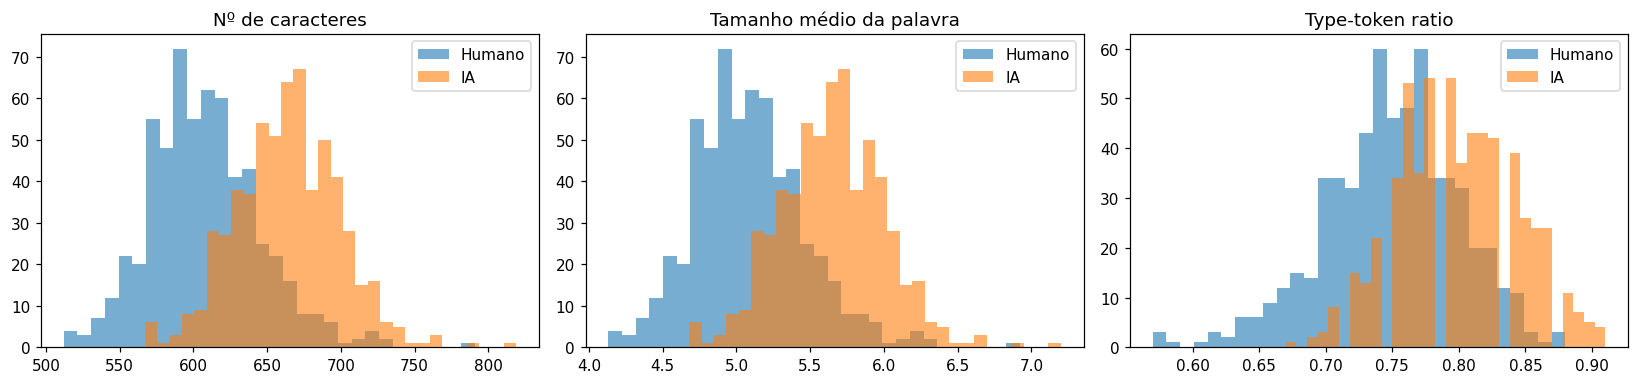

In [ ]:
tmp = df.assign(chars=df.text.str.len(),
                avg_wlen=df.text.map(lambda t: np.mean([len(w) for w in t.split()])),
                ttr=df.text.map(lambda t: len(set(t.lower().split())) / len(t.split())))
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, ttl in zip(axes, ["chars", "avg_wlen", "ttr"], ["Nº de caracteres", "Tamanho médio da palavra", "Type-token ratio"]):
    for lab, nome in [(0, "Humano"), (1, "IA")]:
        ax.hist(tmp[tmp.label == lab][col], bins=30, alpha=.6, label=nome)
    ax.set_title(ttl); ax.legend()
plt.tight_layout(); savefig("eda_basico"); plt.show()

In [ ]:
def top_first_words(d, k=8): return d.text.str.split().str[0].str.lower().value_counts(normalize=True).head(k).round(3)
print("Primeiras palavras (humano):\n", top_first_words(df[df.label == 0]).to_dict())
print("Primeiras palavras (IA):\n",     top_first_words(df[df.label == 1]).to_dict())
marks = {"travessão ( - )": " - ", "dois-pontos": ":", "exclamação": "!", "ponto e vírgula": ";", "parênteses": "(", "aspas": '"'}
print("\nFração de textos com cada marca (diferenças muito grandes indicam possível atalho de formatação):")
display(pd.DataFrame({k: df.groupby("label").text.apply(lambda s: s.str.contains(v, regex=False).mean()) for k, v in marks.items()})
        .rename(index={0: "humano", 1: "IA"}).round(3))

Primeiras palavras (humano):
 {'o': 0.15, 'a': 0.13, 'os': 0.023, 'em': 0.02, 'as': 0.018, 'the': 0.015, 'com': 0.013, 'de': 0.012}
Primeiras palavras (IA):
 {'o': 0.194, 'a': 0.15, 'em': 0.087, 'no': 0.08, 'na': 0.04, 'nesta': 0.012, 'após': 0.012, 'polícia': 0.01}

Fração de textos com cada marca (diferenças muito grandes indicam possível atalho de formatação):


,travessão ( - ),dois-pontos,exclamação,ponto e vírgula,parênteses,aspas
label,,,,,,
humano,0.147,0.172,0.015,0.052,0.533,0.289
IA,0.050,0.045,0.005,0.013,0.304,0.159


In [ ]:
for dom in DOMAINS:
    g = df[df.domain == dom].group.iloc[0]
    print(f"===== {dom.upper()} · tema: {df[df.group == g].topic.iloc[0][:100]} =====")
    for _, r in df[df.group == g].iterrows(): print(f"[{r.source.upper()}] {r.text}\n")

===== WIKI · tema: Centro Desportivo Universitário de Lisboa =====
[HUMAN] O CDUL (Centro Desportivo Universitário de Lisboa), fundado em 1952 por um grupo de indivíduos liderados pelo Engº Vasco Pinto de Magalhães, é um clube multidesportivo da cidade de Lisboa. A sua primeira missão foi a de promover os desportos amadores universitários da área metropolitana de Lisboa. Aproveitando a infraestrutura inaugurada em 1956 do Estádio Universitário de Lisboa, aí fixou a sua atividade que teve início com o atletismo, complementado rapidamente por outras seções como o voleibol, badmington e rugby. Atualmente, desenvolvidas e expandidas as suas atividades desportivas, o CDUL conta com outras modalidades como o judo, ténis e esgrima.

[QWEN] O Centro Desportivo Universitário de Lisboa (CDU) é uma instituição importante para a comunidade esportiva da capital portuguesa. Localizado no centro histórico de Lisboa, próximo à Praça do Comércio, o CDU serve como ponto de encontro e apoio para diversos

In [ ]:
def jaccard(a, b):
    A, B = shingles(a), shingles(b); return len(A & B) / max(len(A | B), 1)

txt_par = df.pivot(index="group", columns="label", values="text")
sim = pd.Series([jaccard(h, a) for h, a in zip(txt_par[0], txt_par[1])], index=txt_par.index, name="Jaccard")
dom_par = df.drop_duplicates("group").set_index("group").domain
display(sim.groupby(dom_par).describe().round(3))
n_alto = int((sim >= 0.2).sum())
display(Markdown(f"**Resumo:** mediana do Jaccard entre o humano e a IA do mesmo tema = {sim.median():.3f} "
                 f"(máximo {sim.max():.3f}); {n_alto} de {len(sim)} pares têm Jaccard >= 0,2."))
for g in sim[sim >= 0.2].sort_values(ascending=False).index[:3]:
    print(f"\n[{g}] Jaccard = {sim[g]:.3f}\nHUMANO: {txt_par.loc[g, 0][:300]}\nIA:     {txt_par.loc[g, 1][:300]}")

,count,mean,std,min,25%,50%,75%,max
domain,,,,,,,,
noticias,320.0,0.000,0.003,0.0,0.0,0.0,0.0,0.032
wiki,279.0,0.001,0.004,0.0,0.0,0.0,0.0,0.027


**Resumo:** mediana do Jaccard entre o humano e a IA do mesmo tema = 0.000 (máximo 0.032); 0 de 599 pares têm Jaccard >= 0,2.

---
# Etapa 6 · Divisão treino/validação/teste e métricas

**Objetivo:** avaliar sem vazamento. A divisão é **por tema (grupo)**: o texto humano e o de IA sobre o mesmo assunto ficam sempre no mesmo conjunto (70% treino · 15% validação · 15% teste).

**Métricas:** accuracy, precision, recall, F1 e ROC-AUC, além de:
- **FPR:** fração de humanos classificados como IA (o erro mais grave: acusação injusta);
- **TPR@FPR5%:** IA detectada quando aceitamos errar só 5% dos humanos;
- **IC95% do AUROC** por bootstrap (o teste é pequeno, então reportamos a incerteza). O bootstrap sorteia **temas**, não textos soltos: o corpus é pareado, e o humano e a IA de um tema entram ou saem juntos do sorteio.

In [ ]:
def assign_split(d, seed=SEED, frac=(0.70, 0.15, 0.15)):
    rng = np.random.RandomState(seed)
    groups = np.array(d.group.unique()); rng.shuffle(groups); n = len(groups)
    tr = set(groups[:int(frac[0] * n)]); va = set(groups[int(frac[0] * n):int((frac[0] + frac[1]) * n)])
    d = d.copy(); d["split"] = d.group.map(lambda g: "train" if g in tr else ("val" if g in va else "test")); return d

df = assign_split(df)
display(df.groupby(["split", "label"]).size().unstack().rename(columns={0: "humano", 1: "IA"}))
def get_splits(): return (df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test"))

label,humano,IA
split,,
test,90,90
train,419,419
val,90,90


In [ ]:
def evaluate(y, p, thr=0.5):
    y, p = np.asarray(y), np.asarray(p); pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel(); two = len(set(y)) > 1
    fpr_, tpr_, _ = roc_curve(y, p) if two else (np.array([0, 1]), np.array([0, 1]), None)
    return {"acc": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0), "f1": f1_score(y, pred, zero_division=0),
            "auroc": roc_auc_score(y, p) if two else np.nan, "fpr": fp / (fp + tn) if (fp + tn) else np.nan,
            "tpr@fpr5%": float(np.interp(0.05, fpr_, tpr_))}

def _units(n, groups):
    if groups is None: return [np.array([i]) for i in range(n)]
    g = np.asarray(groups); return [np.where(g == u)[0] for u in pd.unique(g)]

def auroc_ci(y, p, groups=None, n_boot=1000, seed=SEED):
    y, p = np.asarray(y), np.asarray(p); r = np.random.RandomState(seed); units = _units(len(y), groups); v = []
    for _ in range(n_boot):
        i = np.concatenate([units[k] for k in r.randint(0, len(units), len(units))])
        if len(set(y[i])) > 1: v.append(roc_auc_score(y[i], p[i]))
    return tuple(np.percentile(v, [2.5, 97.5]))

def auroc_diff_ci(y, p1, p2, groups, n_boot=1000, seed=SEED):
    y, p1, p2 = np.asarray(y), np.asarray(p1), np.asarray(p2); r = np.random.RandomState(seed); units = _units(len(y), groups); difs = []
    for _ in range(n_boot):
        i = np.concatenate([units[k] for k in r.randint(0, len(units), len(units))])
        if len(set(y[i])) > 1: difs.append(roc_auc_score(y[i], p1[i]) - roc_auc_score(y[i], p2[i]))
    return roc_auc_score(y, p1) - roc_auc_score(y, p2), tuple(np.percentile(difs, [2.5, 97.5]))

def balance(d, seed=SEED):
    n = d.label.value_counts().min()
    return pd.concat([d[d.label == l].sample(n, random_state=seed) for l in (0, 1)]).sample(frac=1, random_state=seed).reset_index(drop=True)

---
# Etapa 7 · Abordagem clássica

**Objetivo:** estabelecer a linha de base com técnicas tradicionais de PLN.

| Representação | Modelos |
|---|---|
| **Estilometria** (24 atributos: tamanho de frases/palavras, riqueza vocabular, pontuação, stopwords, conectivos, legibilidade…) | Regressão Logística · Random Forest · **SVM (RBF)** |
| **TF-IDF de palavras** (n-gramas de 1 e 2 palavras) | Regressão Logística · **SVM linear** (probabilidades calibradas) |
| **TF-IDF de caracteres** (n-gramas de 3 a 5 caracteres) | Regressão Logística |

Antes dos modelos, a 7.0 mede a **referência ingênua**: prever sempre a classe mais frequente do treino. Ela mostra o piso, o que se obtém sem aprender nada.

Usamos hiperparâmetros padrão (sem busca extensiva), o que é uma limitação declarada: o foco é comparar famílias de técnicas, não maximizar cada uma.

In [ ]:
train_df, val_df, test_df = get_splits()
dummy = DummyClassifier(strategy="most_frequent").fit(np.zeros((len(train_df), 1)), train_df.label)
P_DUMMY = dummy.predict_proba(np.zeros((len(test_df), 1)))[:, 1]
REF_NAME = "Referência ingênua (classe majoritária)"
display(pd.DataFrame([evaluate(test_df.label, P_DUMMY)], index=[REF_NAME]).round(3))
print("Esperado com classes balanceadas: acurácia 0,5, AUROC 0,5 e F1 0 (prevê sempre 'humano').")

,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%
Referência ingênua (classe majoritária),0.5,0.0,0.0,0.0,0.5,0.0,0.05


Esperado com classes balanceadas: acurácia 0,5, AUROC 0,5 e F1 0 (prevê sempre 'humano').


In [ ]:
feats = build_features(tqdm(df.text))
df[FEATURE_COLS] = feats.values
print("Atributos calculados:", feats.shape)

  0%|          | 0/1198 [00:00<?, ?it/s]

Atributos calculados: (1198, 24)


In [ ]:
class SkDetector:
    def __init__(self, name, estimator, cols=None): self.name, self.estimator, self.cols = name, estimator, cols
    def _X(self, d): return d["text"] if self.cols is None else d[self.cols]
    def fit(self, train, val=None): self.model = clone(self.estimator).fit(self._X(train), train["label"]); return self
    def predict_proba(self, d): return self.model.predict_proba(self._X(d))[:, 1]

def LR(): return LogisticRegression(max_iter=3000, class_weight="balanced")
def tfidf_words(): return TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=50000)
def tfidf_chars(): return TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True, max_features=100000)

DETECTOR_BUILDERS = {
    "Estilométrico + LR":       lambda: SkDetector("Estilométrico + LR",  make_pipeline(StandardScaler(), LR()), FEATURE_COLS),
    "Estilométrico + RF":       lambda: SkDetector("Estilométrico + RF",  RandomForestClassifier(300, class_weight="balanced", random_state=SEED, n_jobs=-1), FEATURE_COLS),
    "Estilométrico + SVM":      lambda: SkDetector("Estilométrico + SVM", make_pipeline(StandardScaler(), SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=SEED)), FEATURE_COLS),
    "TF-IDF palavras + LR":     lambda: SkDetector("TF-IDF palavras + LR",  make_pipeline(tfidf_words(), LR())),
    "TF-IDF palavras + SVM":    lambda: SkDetector("TF-IDF palavras + SVM", make_pipeline(tfidf_words(), CalibratedClassifierCV(LinearSVC(class_weight="balanced"), cv=3))),
    "TF-IDF caracteres + LR":   lambda: SkDetector("TF-IDF caracteres + LR", make_pipeline(tfidf_chars(), LR())),
}
CLASSICAL = list(DETECTOR_BUILDERS)
ID_DETECTORS, ID_PROBS, ID_VAL_AUC = {}, {}, {}

def fit_eval_id(names):
    train, val, test = get_splits(); rows = []
    for n in names:
        det = DETECTOR_BUILDERS[n]().fit(train, val)
        p = det.predict_proba(test); ID_DETECTORS[n], ID_PROBS[n] = det, p
        ID_VAL_AUC[n] = roc_auc_score(val.label, det.predict_proba(val))
        rows.append({"detector": n, **evaluate(test.label, p), "AUROC val": ID_VAL_AUC[n]})
    return pd.DataFrame(rows).set_index("detector").round(3)

In [ ]:
tab_classico = fit_eval_id(CLASSICAL)
display(tab_classico)
best_c = tab_classico["auroc"].idxmax()
fam = {"estilometria": [n for n in CLASSICAL if n.startswith("Estilom")],
       "TF-IDF de palavras": [n for n in CLASSICAL if n.startswith("TF-IDF palavras")],
       "TF-IDF de caracteres": [n for n in CLASSICAL if n.startswith("TF-IDF caracteres")]}
melhor_fam = {f: tab_classico.loc[ns, "auroc"].max() for f, ns in fam.items()}
display(Markdown(f"**Resumo:** entre os métodos clássicos, o melhor foi **{best_c}** (AUROC = {tab_classico.loc[best_c,'auroc']:.3f}, "
                 f"FPR = {tab_classico.loc[best_c,'fpr']:.1%}). Melhor AUROC por família: "
                 + ", ".join(f"{f} = {v:.3f}" for f, v in melhor_fam.items())
                 + f". A família com mais sinal foi **{max(melhor_fam, key=melhor_fam.get)}**."))

,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%,AUROC val
detector,,,,,,,,
Estilométrico + LR,0.856,0.856,0.856,0.856,0.917,0.144,0.644,0.965
Estilométrico + RF,0.844,0.844,0.844,0.844,0.911,0.156,0.667,0.951
Estilométrico + SVM,0.828,0.855,0.789,0.821,0.912,0.133,0.656,0.961
TF-IDF palavras + LR,0.889,0.850,0.944,0.895,0.964,0.167,0.811,0.965
TF-IDF palavras + SVM,0.872,0.825,0.944,0.881,0.967,0.200,0.800,0.968
TF-IDF caracteres + LR,0.867,0.824,0.933,0.875,0.957,0.200,0.844,0.974


**Resumo:** entre os métodos clássicos, o melhor foi **TF-IDF palavras + SVM** (AUROC = 0.967, FPR = 20.0%). Melhor AUROC por família: estilometria = 0.917, TF-IDF de palavras = 0.967, TF-IDF de caracteres = 0.957. A família com mais sinal foi **TF-IDF de palavras**.

---
# Etapa 8 · Mineração de dados: padrões de escrita

**Objetivo:** responder à **PQ2**: existem padrões de escrita associados às duas classes? Além de medir se o modelo acerta, perguntamos **o que** diferencia humano e IA, **com que força** e **se isso vale nos dois domínios**.

Para cada atributo calculamos: medianas por classe, teste de Mann-Whitney (com correção de Bonferroni) e o **delta de Cliff** (tamanho de efeito: |δ| < 0,15 desprezível · < 0,33 pequeno · < 0,47 médio · ≥ 0,47 grande). A coluna `consistente` indica se o sinal é o mesmo na Wikipedia e nas notícias.

O Mann-Whitney supõe amostras independentes, mas o corpus é pareado (1 humano e 1 IA por tema). A 8.1b repete o teste com Wilcoxon pareado: compara o humano e a IA **do mesmo tema**.

In [ ]:
def magnitude(d):
    d = abs(d); return "desprezível" if d < .147 else "pequeno" if d < .33 else "médio" if d < .474 else "grande"

def cliff(a, h):
    u, p = mannwhitneyu(a, h, alternative="two-sided"); return 2 * u / (len(a) * len(h)) - 1, p

rows = []
for c in FEATURE_COLS:
    a, h = df.loc[df.label == 1, c].values, df.loc[df.label == 0, c].values
    dl, p = cliff(a, h)
    r = {"atributo": FEATURE_LABELS[c], "mediana humano": np.median(h), "mediana IA": np.median(a), "δ Cliff": dl, "magnitude": magnitude(dl), "p": p}
    for dom in DOMAINS:
        r[f"δ {dom}"] = cliff(df.loc[(df.label == 1) & (df.domain == dom), c].values, df.loc[(df.label == 0) & (df.domain == dom), c].values)[0]
    rows.append(r)
efeitos = pd.DataFrame(rows)
efeitos["p (Bonferroni)"] = np.minimum(efeitos.p * len(efeitos), 1)
efeitos["consistente"] = np.sign(efeitos[f"δ {DOMAINS[0]}"]) == np.sign(efeitos[f"δ {DOMAINS[1]}"])
efeitos = efeitos.reindex(efeitos["δ Cliff"].abs().sort_values(ascending=False).index).drop(columns="p").reset_index(drop=True)
display(efeitos.round(3)); efeitos.to_csv(os.path.join(PROJ, "data", "tabela_efeitos.csv"), index=False)

top = efeitos.iloc[0]
display(Markdown(f"**Resumo:** o atributo mais discriminativo é **{top['atributo']}** (δ = {top['δ Cliff']:.2f}, efeito {top['magnitude']}; "
                 f"textos de IA têm {'valores maiores' if top['δ Cliff'] > 0 else 'valores menores'}). "
                 f"{int((efeitos['p (Bonferroni)'] < .05).sum())} de {len(efeitos)} atributos diferem de forma significativa; "
                 f"{int(efeitos['consistente'].sum())} mantêm o mesmo sentido nos dois domínios."))

,atributo,mediana humano,mediana IA,δ Cliff,magnitude,δ wiki,δ noticias,p (Bonferroni),consistente
0,Tamanho médio da palavra (letras),4.843,5.480,0.766,grande,0.799,0.738,0.000,True
1,Sílabas por palavra (aprox.),2.101,2.376,0.753,grande,0.796,0.719,0.000,True
2,Legibilidade (Flesch-PT; maior = mais fácil),49.605,24.689,-0.742,grande,-0.794,-0.697,0.000,True
3,Proporção de palavras longas (>=9 letras),0.130,0.200,0.683,grande,0.746,0.627,0.000,True
4,Proporção de maiúsculas,0.035,0.018,-0.628,grande,-0.726,-0.552,0.000,True
5,Riqueza vocabular (type-token ratio),0.727,0.782,0.602,grande,0.687,0.533,0.000,True
6,Palavras que aparecem uma só vez,0.581,0.660,0.596,grande,0.667,0.549,0.000,True
7,Proporção de dígitos,0.010,0.003,-0.449,médio,-0.512,-0.428,0.000,True
8,Repetição de bigramas,0.030,0.010,-0.425,médio,-0.488,-0.386,0.000,True
9,Variação relativa do tamanho das frases,0.429,0.319,-0.388,médio,-0.443,-0.337,0.000,True


**Resumo:** o atributo mais discriminativo é **Tamanho médio da palavra (letras)** (δ = 0.77, efeito grande; textos de IA têm valores maiores). 21 de 24 atributos diferem de forma significativa; 21 mantêm o mesmo sentido nos dois domínios.

In [ ]:
pares_feat = df.pivot_table(index="group", columns="label", values=FEATURE_COLS)
linhas_w = []
for c in FEATURE_COLS:
    dif = pares_feat[(c, 1)] - pares_feat[(c, 0)]
    if np.allclose(dif, 0): continue
    pv = wilcoxon(dif).pvalue
    linhas_w.append({"atributo": FEATURE_LABELS[c], "mediana (IA - humano)": dif.median(),
                     "pares com IA > humano": (dif > 0).mean(), "pares com IA < humano": (dif < 0).mean(),
                     "p pareado (Bonferroni)": min(pv * len(FEATURE_COLS), 1.0)})
tab_wilcoxon = pd.DataFrame(linhas_w).sort_values("p pareado (Bonferroni)").reset_index(drop=True)
display(tab_wilcoxon.round(4)); tab_wilcoxon.to_csv(os.path.join(PROJ, "data", "tabela_wilcoxon_pareado.csv"), index=False)

sig_mw = set(efeitos.loc[efeitos["p (Bonferroni)"] < .05, "atributo"])
sig_w = set(tab_wilcoxon.loc[tab_wilcoxon["p pareado (Bonferroni)"] < .05, "atributo"])
so_mw, so_w = sorted(sig_mw - sig_w), sorted(sig_w - sig_mw)
display(Markdown(f"**Resumo:** {len(sig_w)} de {len(FEATURE_COLS)} atributos diferem no teste pareado (Bonferroni, p < 0,05), "
                 f"contra {len(sig_mw)} no Mann-Whitney."
                 + (f" Significativos só no Mann-Whitney: {', '.join(so_mw)}." if so_mw else "")
                 + (f" Significativos só no pareado: {', '.join(so_w)}." if so_w else "")))

,atributo,mediana (IA - humano),pares com IA > humano,pares com IA < humano,p pareado (Bonferroni)
0,Tamanho médio da palavra (letras),0.5951,0.9299,0.0701,0.0000
1,Sílabas por palavra (aprox.),0.2590,0.9282,0.0684,0.0000
2,Legibilidade (Flesch-PT; maior = mais fácil),-23.7146,0.0735,0.9265,0.0000
3,Proporção de palavras longas (>=9 letras),0.0714,0.8731,0.1152,0.0000
4,Proporção de maiúsculas,-0.0150,0.1352,0.8648,0.0000
5,Riqueza vocabular (type-token ratio),0.0569,0.8030,0.1870,0.0000
6,Palavras que aparecem uma só vez,0.0800,0.7896,0.2053,0.0000
7,Proporção de dígitos,-0.0063,0.1553,0.7112,0.0000
8,Repetição de bigramas,-0.0116,0.2521,0.6811,0.0000
9,Variação relativa do tamanho das frases,-0.1103,0.3038,0.6962,0.0000


**Resumo:** 21 de 24 atributos diferem no teste pareado (Bonferroni, p < 0,05), contra 21 no Mann-Whitney.

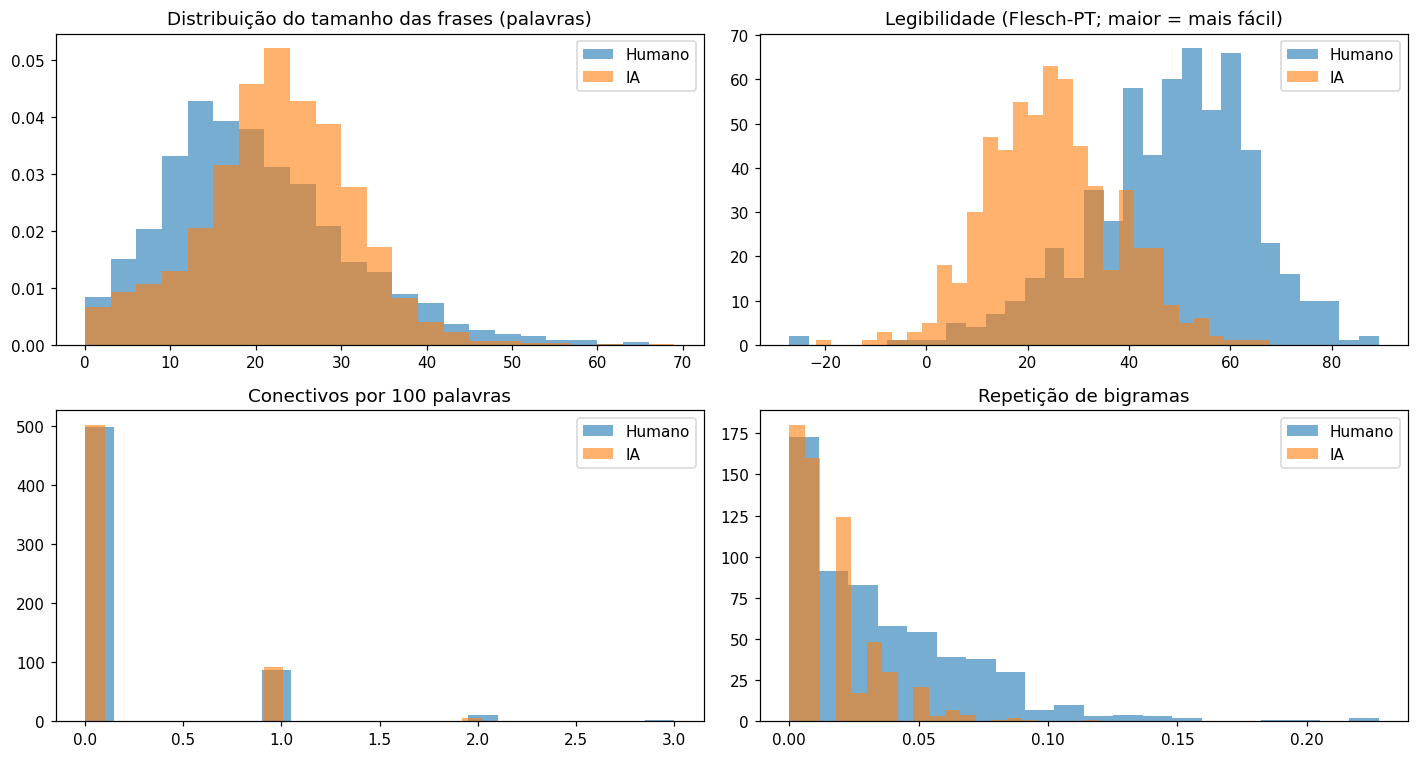

,humano,IA,diferença (IA−humano)
além disso,0.017,0.080,0.063
porém,0.020,0.003,-0.017
logo,0.022,0.008,-0.013
por exemplo,0.020,0.007,-0.013
por isso,0.012,0.002,-0.010
entretanto,0.010,0.000,-0.010
assim,0.038,0.030,-0.008
no entanto,0.023,0.028,0.005
de fato,0.005,0.000,-0.005
portanto,0.005,0.002,-0.003


In [ ]:
sent_len = {lab: [len(s.split()) for t in df[df.label == lab].text for s in split_sentences(t)] for lab in (0, 1)}
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
for lab, nome in [(0, "Humano"), (1, "IA")]:
    ax[0, 0].hist(sent_len[lab], bins=range(0, 70, 3), alpha=.6, density=True, label=nome)
    ax[0, 1].hist(df[df.label == lab].st_flesch, bins=30, alpha=.6, label=nome)
    ax[1, 0].hist(df[df.label == lab].st_connectives, bins=20, alpha=.6, label=nome)
    ax[1, 1].hist(df[df.label == lab].st_rep_bigram, bins=20, alpha=.6, label=nome)
for a, t in zip(ax.ravel(), ["Distribuição do tamanho das frases (palavras)", "Legibilidade (Flesch-PT; maior = mais fácil)",
                             "Conectivos por 100 palavras", "Repetição de bigramas"]):
    a.set_title(t); a.legend()
plt.tight_layout(); savefig("padroes_escrita"); plt.show()

conn = {lab: Counter() for lab in (0, 1)}
for lab in (0, 1):
    for t in df[df.label == lab].text:
        low = t.lower()
        for c_ in CONNECTIVES: conn[lab][c_] += len(re.findall(r"\b" + re.escape(c_) + r"\b", low))
tot = {lab: (df.label == lab).sum() * TRUNC_WORDS / 100 for lab in (0, 1)}
tab_conn = pd.DataFrame({"humano": {k: v / tot[0] for k, v in conn[0].items()}, "IA": {k: v / tot[1] for k, v in conn[1].items()}})
tab_conn["diferença (IA−humano)"] = tab_conn["IA"] - tab_conn["humano"]
display(tab_conn.reindex(tab_conn["diferença (IA−humano)"].abs().sort_values(ascending=False).index).head(10).round(3))

### 8.3 Quais atributos o modelo mais usa?
Comparamos a **importância** no Random Forest e os **coeficientes** da regressão logística (atributos padronizados). Atributos com efeito forte na tabela 8.1 *e* importância alta no modelo são os mais confiáveis para a discussão.

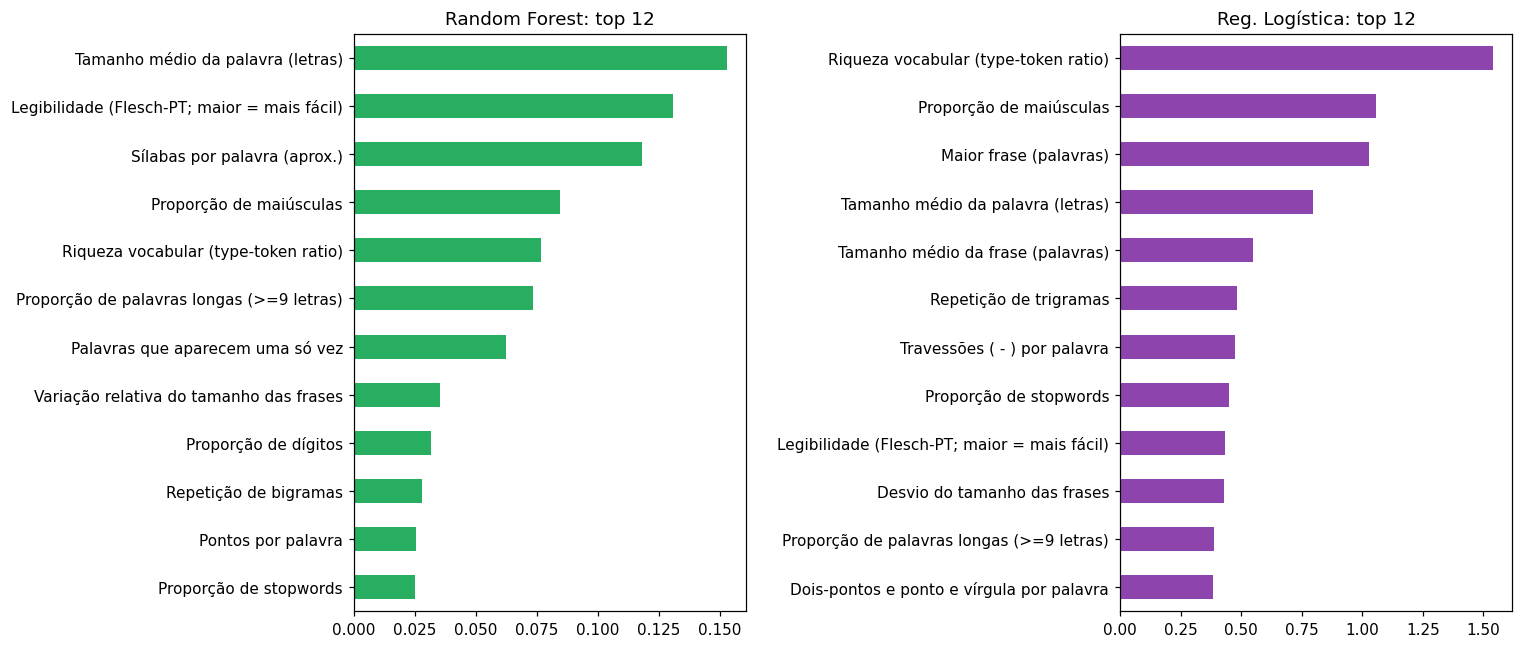

In [ ]:
rf = ID_DETECTORS["Estilométrico + RF"].model
lr = ID_DETECTORS["Estilométrico + LR"].model.steps[-1][1]
imp = pd.DataFrame({"RF (importância)": rf.feature_importances_, "LR (|coef| padronizado)": np.abs(lr.coef_[0])},
                   index=[FEATURE_LABELS[c] for c in FEATURE_COLS])
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
imp["RF (importância)"].sort_values().tail(12).plot.barh(ax=ax[0], color="#27ae60", title="Random Forest: top 12")
imp["LR (|coef| padronizado)"].sort_values().tail(12).plot.barh(ax=ax[1], color="#8e44ad", title="Reg. Logística: top 12")
plt.tight_layout(); savefig("importancia_atributos"); plt.show()

### 8.4 Clustering (não supervisionado)
Sem usar os rótulos, os documentos formam grupos? E esses grupos correspondem à **autoria** (humano/IA) ou a outra coisa (**domínio**, **gerador**)? Medimos com ARI e NMI (0 = nenhuma relação, 1 = idêntico).

In [ ]:
Xs = StandardScaler().fit_transform(df[FEATURE_COLS])
res_k = []
for k in (2, 4):
    cl = KMeans(k, n_init=10, random_state=SEED).fit_predict(Xs)
    for nome, ref in [("autoria (humano/IA)", df.label), ("domínio", df.domain), ("fonte (humano/qwen/phi)", df.source)]:
        res_k.append({"k": k, "comparado com": nome, "ARI": adjusted_rand_score(ref, cl), "NMI": normalized_mutual_info_score(ref, cl)})
res_k = pd.DataFrame(res_k); display(res_k.round(3))
cl2 = KMeans(2, n_init=10, random_state=SEED).fit_predict(Xs)
display(pd.crosstab(cl2, df.label.map({0: "humano", 1: "IA"}), rownames=["cluster"]))
best_ref = res_k[res_k.k == 2].set_index("comparado com").ARI.idxmax()
display(Markdown(f"**Resumo:** com k = 2, os clusters se alinham mais a **{best_ref}** "
                 f"(ARI = {res_k[(res_k.k==2)].set_index('comparado com').ARI.max():.2f}). "
                 f"{'Isso sugere que, sem supervisão, a diferença de domínio pesa mais que a de autoria.' if best_ref != 'autoria (humano/IA)' else 'Há estrutura de autoria detectável sem supervisão.'}"))

,k,comparado com,ARI,NMI
0,2,autoria (humano/IA),0.498,0.411
1,2,domínio,0.008,0.005
2,2,fonte (humano/qwen/phi),0.331,0.330
3,4,autoria (humano/IA),0.360,0.320
4,4,domínio,0.004,0.006
5,4,fonte (humano/qwen/phi),0.205,0.274


label,IA,humano
cluster,,
0,52,475
1,547,124


**Resumo:** com k = 2, os clusters se alinham mais a **autoria (humano/IA)** (ARI = 0.50). Há estrutura de autoria detectável sem supervisão.

### 8.5 Visualização do espaço de atributos (PCA e t-SNE)

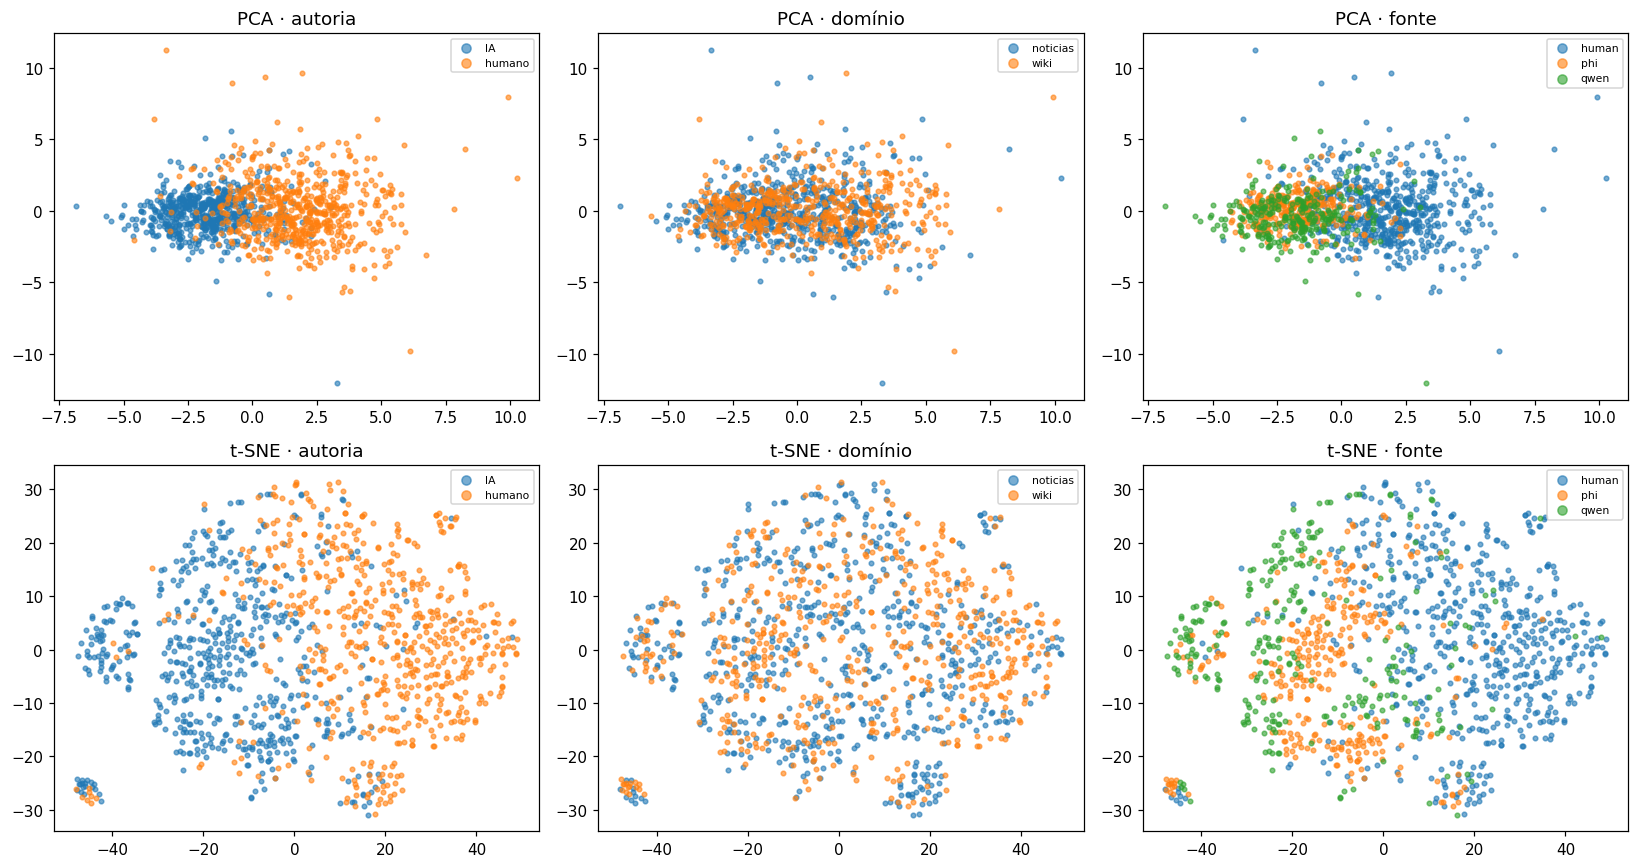

In [ ]:
Zp = PCA(2, random_state=SEED).fit_transform(Xs)
Zt = TSNE(2, perplexity=30, init="pca", random_state=SEED).fit_transform(Xs)

def scatter_by(ax, Z, cats, title):
    for c in sorted(pd.unique(cats)):
        m = np.asarray(cats) == c; ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=.6, label=str(c))
    ax.set_title(title); ax.legend(fontsize=7, markerscale=2)

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (Z, nome) in enumerate([(Zp, "PCA"), (Zt, "t-SNE")]):
    scatter_by(ax[row, 0], Z, df.label.map({0: "humano", 1: "IA"}).values, f"{nome} · autoria")
    scatter_by(ax[row, 1], Z, df.domain.values, f"{nome} · domínio")
    scatter_by(ax[row, 2], Z, df.source.values, f"{nome} · fonte")
plt.tight_layout(); savefig("pca_tsne_estilometria"); plt.show()

---
# Etapa 9 · Deep learning: fine-tuning do BERTimbau

**Objetivo:** treinar um classificador binário baseado em **BERTimbau** (BERT pré-treinado em português) e comparar com a linha de base clássica.

- Laço de treino em PyTorch com precisão mista; 3 épocas; guarda o **melhor estado segundo o AUROC de validação** (o teste não participa da escolha).
- Registramos a curva de treino e depois visualizamos as **representações internas** do modelo antes e depois do fine-tuning.

In [ ]:
class BertDetector:
    name = "BERTimbau (fine-tuning)"
    def __init__(self, epochs=3, lr=3e-5, bs=16, max_len=BERT_MAX_LEN, seed=None):
        self.epochs, self.lr, self.bs, self.max_len, self.seed, self.history = epochs, lr, bs, max_len, seed, []

    def fit(self, train, val=None):
        set_seed(SEED if self.seed is None else self.seed); self.history = []
        self.tok = AutoTokenizer.from_pretrained(BERT_MODEL)
        self.model = AutoModelForSequenceClassification.from_pretrained(BERT_MODEL, num_labels=2).to(DEVICE)
        enc = self.tok(list(train.text), truncation=True, max_length=self.max_len, padding=True, return_tensors="pt")
        dl = DataLoader(TensorDataset(enc["input_ids"], enc["attention_mask"], torch.tensor(train.label.values)), batch_size=self.bs, shuffle=True)
        opt = torch.optim.AdamW(self.model.parameters(), lr=self.lr, weight_decay=0.01)
        total = len(dl) * self.epochs; sch = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
        amp = DEVICE == "cuda"; scaler = torch.amp.GradScaler("cuda", enabled=amp); best, state = -1, None
        for ep in range(self.epochs):
            self.model.train(); tot = 0
            for ids, att, y in dl:
                ids, att, y = ids.to(DEVICE), att.to(DEVICE), y.to(DEVICE); opt.zero_grad()
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=amp):
                    loss = self.model(input_ids=ids, attention_mask=att, labels=y).loss
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sch.step(); tot += loss.item()
            h = {"época": ep + 1, "loss treino": tot / len(dl)}
            if val is not None and val.label.nunique() > 1:
                h["AUROC val"] = roc_auc_score(val.label, self.predict_proba(val))
                if h["AUROC val"] > best: best = h["AUROC val"]; state = {k: v.detach().cpu().clone() for k, v in self.model.state_dict().items()}
            self.history.append(h); print("  ", {k: round(v, 4) for k, v in h.items()})
        if state is not None: self.model.load_state_dict(state)
        return self

    def _batches(self, texts, bs):
        for i in range(0, len(texts), bs):
            yield self.tok(texts[i:i + bs], truncation=True, max_length=self.max_len, padding=True, return_tensors="pt").to(DEVICE)

    @torch.no_grad()
    def predict_proba(self, d, bs=64):
        self.model.eval(); out = []
        for enc in self._batches(list(d["text"]), bs):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                lg = self.model(**enc).logits
            out += torch.softmax(lg.float(), -1)[:, 1].cpu().tolist()
        return np.array(out)

    @torch.no_grad()
    def embed(self, texts, bs=64):
        self.model.eval(); out = []
        for enc in self._batches(list(texts), bs):
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
                h = self.model.bert(**enc).last_hidden_state
            m = enc["attention_mask"].unsqueeze(-1).float(); out.append(((h.float() * m).sum(1) / m.sum(1)).cpu().numpy())
        return np.vstack(out)

    def free(self): del self.model; gc.collect(); torch.cuda.empty_cache()

BERT_NAME = "BERTimbau (fine-tuning)"
DETECTOR_BUILDERS[BERT_NAME] = lambda: BertDetector()
tab_bert = fit_eval_id([BERT_NAME]); display(tab_bert)

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

   {'época': 1, 'loss treino': 0.4696, 'AUROC val': np.float64(0.9835)}
   {'época': 2, 'loss treino': 0.1147, 'AUROC val': np.float64(0.9933)}
   {'época': 3, 'loss treino': 0.0309, 'AUROC val': np.float64(0.9958)}


,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%,AUROC val
detector,,,,,,,,
BERTimbau (fine-tuning),0.922,0.888,0.967,0.926,0.977,0.122,0.922,0.996


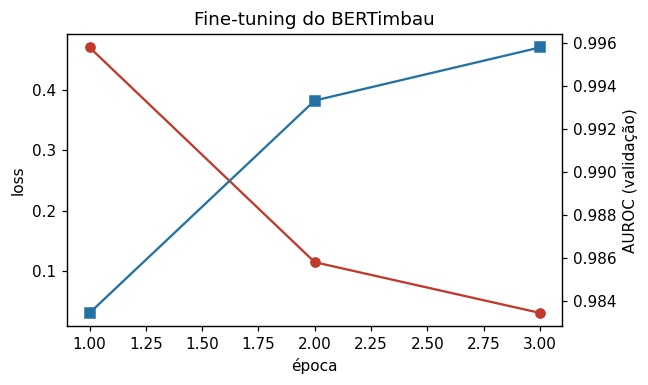

In [ ]:
hist = pd.DataFrame(ID_DETECTORS[BERT_NAME].history).set_index("época")
fig, ax = plt.subplots(figsize=(6, 3.6)); hist["loss treino"].plot(ax=ax, marker="o", color="#c0392b", label="loss de treino")
ax2 = ax.twinx(); hist["AUROC val"].plot(ax=ax2, marker="s", color="#2471a3", label="AUROC val"); ax.set_ylabel("loss"); ax2.set_ylabel("AUROC (validação)")
ax.set_title("Fine-tuning do BERTimbau"); plt.tight_layout(); savefig("bert_curva_treino"); plt.show()

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


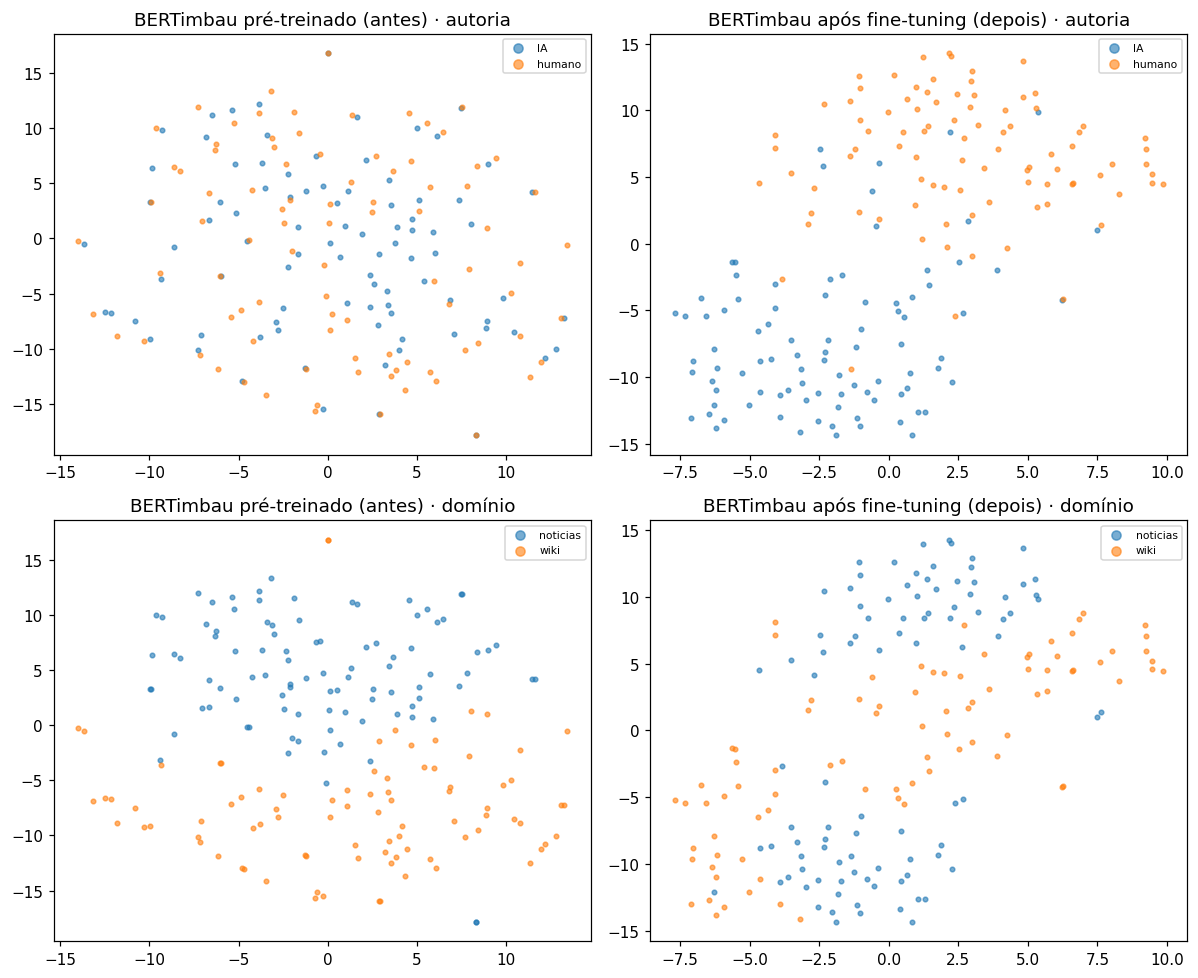

In [ ]:
_, _, test_df = get_splits()
base_tok = AutoTokenizer.from_pretrained(BERT_MODEL); base_model = AutoModel.from_pretrained(BERT_MODEL).to(DEVICE).eval()

@torch.no_grad()
def embed_base(texts, bs=64):
    out = []
    for i in range(0, len(texts), bs):
        enc = base_tok(texts[i:i + bs], truncation=True, max_length=BERT_MAX_LEN, padding=True, return_tensors="pt").to(DEVICE)
        h = base_model(**enc).last_hidden_state; m = enc["attention_mask"].unsqueeze(-1).float()
        out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    return np.vstack(out)

E_before = embed_base(list(test_df.text)); E_after = ID_DETECTORS[BERT_NAME].embed(test_df.text)
del base_model; gc.collect(); torch.cuda.empty_cache()
perp = max(5, min(30, len(test_df) // 4))
fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for j, (E, nome) in enumerate([(E_before, "BERTimbau pré-treinado (antes)"), (E_after, "BERTimbau após fine-tuning (depois)")]):
    Z = TSNE(2, perplexity=perp, init="pca", random_state=SEED).fit_transform(E)
    scatter_by(ax[0, j], Z, test_df.label.map({0: "humano", 1: "IA"}).values, nome + " · autoria")
    scatter_by(ax[1, j], Z, test_df.domain.values, nome + " · domínio")
plt.tight_layout(); savefig("tsne_bertimbau"); plt.show()

---
# Etapa 10 · Comparação dos modelos (mesma distribuição)

**Objetivo:** responder à **PQ1** com todos os modelos lado a lado no conjunto de teste, com incerteza.

- **10.1** tabela comparativa, com a referência ingênua na primeira linha e IC95% do AUROC por bootstrap de temas;
- **10.2** IC95% da **diferença** de AUROC entre pares de modelos, nos mesmos sorteios;
- **10.3** BERTimbau treinado com 3 sementes (média ± desvio).

,acc,precision,recall,f1,AUROC,IC95% inf,IC95% sup,FPR,TPR@FPR5%
detector,,,,,,,,,
Referência ingênua (classe majoritária),0.500,0.000,0.000,0.000,0.500,NaN,NaN,0.000,0.050
BERTimbau (fine-tuning),0.922,0.888,0.967,0.926,0.977,0.958,0.992,0.122,0.922
TF-IDF palavras + SVM,0.872,0.825,0.944,0.881,0.967,0.945,0.985,0.200,0.800
TF-IDF palavras + LR,0.889,0.850,0.944,0.895,0.964,0.942,0.983,0.167,0.811
TF-IDF caracteres + LR,0.867,0.824,0.933,0.875,0.957,0.931,0.980,0.200,0.844
Estilométrico + LR,0.856,0.856,0.856,0.856,0.917,0.881,0.951,0.144,0.644
Estilométrico + SVM,0.828,0.855,0.789,0.821,0.912,0.872,0.946,0.133,0.656
Estilométrico + RF,0.844,0.844,0.844,0.844,0.911,0.869,0.947,0.156,0.667


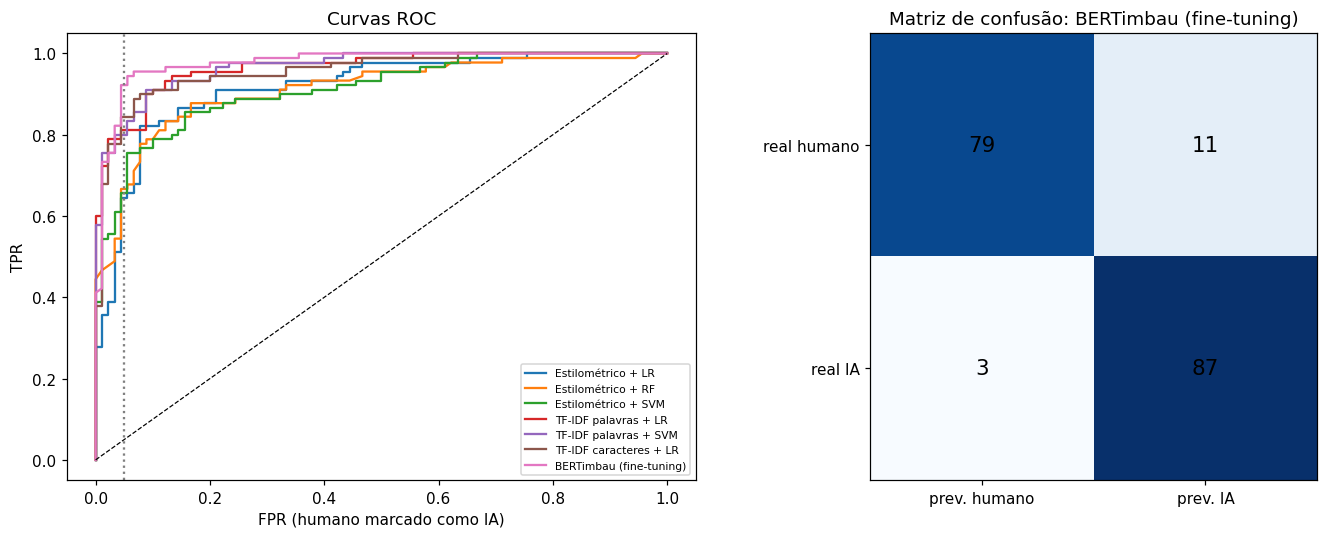

**Resumo (PQ1):** o melhor modelo na mesma distribuição é **BERTimbau (fine-tuning)** (AUROC = 0.977, IC95% [0.958, 0.992], FPR = 12.2%). A referência ingênua fica em AUROC 0.50 e F1 0.00. A 10.2 testa se a vantagem sobre os outros modelos é maior que a variação do sorteio do teste. Este é o cenário mais favorável: a Etapa 11 testa o que acontece quando as condições mudam.

In [ ]:
_, _, test_df = get_splits(); rows = []
for n, p in ID_PROBS.items():
    m = evaluate(test_df.label, p); lo, hi = auroc_ci(test_df.label, p, groups=test_df.group)
    rows.append({"detector": n, "acc": m["acc"], "precision": m["precision"], "recall": m["recall"], "f1": m["f1"],
                 "AUROC": m["auroc"], "IC95% inf": lo, "IC95% sup": hi, "FPR": m["fpr"], "TPR@FPR5%": m["tpr@fpr5%"]})
tab_id = pd.DataFrame(rows).set_index("detector").sort_values("AUROC", ascending=False)

m0 = evaluate(test_df.label, P_DUMMY)
ref_row = pd.DataFrame([{"acc": m0["acc"], "precision": m0["precision"], "recall": m0["recall"], "f1": m0["f1"], "AUROC": m0["auroc"],
                         "IC95% inf": np.nan, "IC95% sup": np.nan, "FPR": m0["fpr"], "TPR@FPR5%": m0["tpr@fpr5%"]}], index=[REF_NAME])
tab_artigo = pd.concat([ref_row, tab_id]); tab_artigo.index.name = "detector"
display(tab_artigo.round(3)); tab_artigo.round(4).to_csv(os.path.join(PROJ, "data", "resultados_mesma_distribuicao.csv"))

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for n, p in ID_PROBS.items():
    f, t, _ = roc_curve(test_df.label, p); ax[0].plot(f, t, label=n)
ax[0].plot([0, 1], [0, 1], "k--", lw=.8); ax[0].axvline(.05, color="gray", ls=":")
ax[0].set(xlabel="FPR (humano marcado como IA)", ylabel="TPR", title="Curvas ROC"); ax[0].legend(fontsize=7)
best_n = tab_id.index[0]; cm = confusion_matrix(test_df.label, ID_PROBS[best_n] >= .5)
ax[1].imshow(cm, cmap="Blues"); ax[1].set_xticks([0, 1], ["prev. humano", "prev. IA"]); ax[1].set_yticks([0, 1], ["real humano", "real IA"])
for i in range(2):
    for j in range(2): ax[1].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax[1].set_title(f"Matriz de confusão: {best_n}"); plt.tight_layout(); savefig("comparacao_roc_confusao"); plt.show()

b = tab_id.iloc[0]
display(Markdown(f"**Resumo (PQ1):** o melhor modelo na mesma distribuição é **{best_n}** (AUROC = {b['AUROC']:.3f}, "
                 f"IC95% [{b['IC95% inf']:.3f}, {b['IC95% sup']:.3f}], FPR = {b['FPR']:.1%}). "
                 f"A referência ingênua fica em AUROC {m0['auroc']:.2f} e F1 {m0['f1']:.2f}. "
                 "A 10.2 testa se a vantagem sobre os outros modelos é maior que a variação do sorteio do teste. "
                 "Este é o cenário mais favorável: a Etapa 11 testa o que acontece quando as condições mudam."))

In [ ]:
_, _, test_df = get_splits()
best_estilo = tab_id.loc[[n for n in tab_id.index if n.startswith("Estilom")], "AUROC"].idxmax()
comparacoes = [(BERT_NAME, best_c),
               (tab_id.index[0], tab_id.index[1]),
               (best_c, best_estilo)]
linhas_d = []
for a_, b_ in dict.fromkeys(comparacoes):
    if a_ == b_: continue
    dif, (lo, hi) = auroc_diff_ci(test_df.label, ID_PROBS[a_], ID_PROBS[b_], test_df.group)
    linhas_d.append({"modelo A": a_, "modelo B": b_, "AUROC A - B": dif, "IC95% inf": lo, "IC95% sup": hi,
                     "leitura": "A melhor que B" if lo > 0 else ("B melhor que A" if hi < 0 else "IC contém 0: sem diferença clara")})
tab_dif = pd.DataFrame(linhas_d)
display(tab_dif.round(4)); tab_dif.round(4).to_csv(os.path.join(PROJ, "data", "diferenca_auroc_bootstrap.csv"), index=False)

,modelo A,modelo B,AUROC A - B,IC95% inf,IC95% sup,leitura
0,BERTimbau (fine-tuning),TF-IDF palavras + SVM,0.0102,-0.0123,0.0358,IC contém 0: sem diferença clara
1,TF-IDF palavras + SVM,Estilométrico + LR,0.0494,0.0165,0.0870,A melhor que B


In [ ]:
SEEDS_BERT = (42, 7, 2026)
train, val, test = get_splits(); por_semente = []
for s in SEEDS_BERT:
    if s == SEED:
        p_s = ID_PROBS[BERT_NAME]
    else:
        print(f"Semente {s}:"); det = BertDetector(seed=s).fit(train, val); p_s = det.predict_proba(test); det.free()
    por_semente.append({"semente": s, **evaluate(test.label, p_s)})
set_seed(SEED)
tab_sementes = pd.DataFrame(por_semente).set_index("semente")
ms = tab_sementes.agg(["mean", "std"])
display(tab_sementes.round(3)); display(ms.round(3))
tab_sementes.round(4).to_csv(os.path.join(PROJ, "data", "bertimbau_sementes.csv"))
display(Markdown(f"**Resumo:** em {len(SEEDS_BERT)} sementes, o BERTimbau tem AUROC {ms.loc['mean', 'auroc']:.3f} ± {ms.loc['std', 'auroc']:.3f}, "
                 f"F1 {ms.loc['mean', 'f1']:.3f} ± {ms.loc['std', 'f1']:.3f} e FPR {ms.loc['mean', 'fpr']:.1%} ± {ms.loc['std', 'fpr']:.1%}."))

Semente 7:


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.4256, 'AUROC val': np.float64(0.9921)}
   {'época': 2, 'loss treino': 0.1313, 'AUROC val': np.float64(0.9981)}
   {'época': 3, 'loss treino': 0.0296, 'AUROC val': np.float64(0.9977)}
Semente 2026:


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5307, 'AUROC val': np.float64(0.9894)}
   {'época': 2, 'loss treino': 0.1339, 'AUROC val': np.float64(0.9953)}
   {'época': 3, 'loss treino': 0.0358, 'AUROC val': np.float64(0.9951)}


,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%
semente,,,,,,,
42,0.922,0.888,0.967,0.926,0.977,0.122,0.922
7,0.939,0.934,0.944,0.939,0.980,0.067,0.900
2026,0.928,0.914,0.944,0.929,0.985,0.089,0.911


,acc,precision,recall,f1,auroc,fpr,tpr@fpr5%
mean,0.930,0.912,0.952,0.931,0.981,0.093,0.911
std,0.008,0.023,0.013,0.007,0.004,0.028,0.011


**Resumo:** em 3 sementes, o BERTimbau tem AUROC 0.981 ± 0.004, F1 0.931 ± 0.007 e FPR 9.3% ± 2.8%.

---
# Etapa 11 · Generalização: quando as condições mudam

**Objetivo:** responder à **PQ3**. Um detector que acerta na distribuição do treino pode falhar fora dela.

| Experimento | Treino | Teste |
|---|---|---|
| **11.1 Entre geradores** | humanos + textos do **Qwen** | humanos + textos do **Phi** (nunca visto) |
| | humanos + textos do **Phi** | humanos + textos do **Qwen** |
| **11.2 Entre domínios** | Wikipedia | notícias (e vice-versa) |
| **11.3 Testes de estresse** | (modelos já treinados) | texto curto (50 e 30 palavras) e texto com ruído/erros |
| **11.4 Gerador externo** | (modelos já treinados com Qwen + Phi) | humanos do teste + textos do **Gemini** sobre os mesmos temas |
| **11.2b Controles** | o mesmo treino reduzido de 11.1 e 11.2 | o **mesmo** gerador ou domínio do treino |

Nos experimentos 11.1, 11.2 e 11.2b todos os detectores são retreinados (os de BERTimbau levam ~2–4 min cada).

Além do AUROC, a 11.6 mostra o **FPR com limiar 0,5**. O AUROC mede se o detector ordena bem os textos; o FPR mede quantos humanos o limiar fixo acusa de ser IA. Fora das condições de treino os dois podem divergir.

In [ ]:
RESULTS = [{"experimento": "0. Mesma distribuição", "detector": n, **evaluate(test_df.label, p)} for n, p in ID_PROBS.items()]

def run_experiment(exp, train, val, test, names=None):
    names = names or list(DETECTOR_BUILDERS); train, val, test = balance(train), balance(val), balance(test)
    print(f"\n### {exp} | treino={len(train)} val={len(val)} teste={len(test)}")
    for n in names:
        print(" ->", n); det = DETECTOR_BUILDERS[n]().fit(train, val)
        RESULTS.append({"experimento": exp, "detector": n, **evaluate(test.label, det.predict_proba(test))})
        if hasattr(det, "free"): det.free()
    pd.DataFrame(RESULTS).to_csv(os.path.join(PROJ, "data", "resultados_robustez_parcial.csv"), index=False)

train, val, test = get_splits()
def only(d, gen): return d[(d.label == 0) | (d.source == gen)]
run_experiment("1a. treina Qwen → testa Phi", only(train, "qwen"), only(val, "qwen"), only(test, "phi"))
run_experiment("1b. treina Phi → testa Qwen", only(train, "phi"),  only(val, "phi"),  only(test, "qwen"))


### 1a. treina Qwen → testa Phi | treino=388 val=94 teste=102
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.6224, 'AUROC val': np.float64(0.9882)}
   {'época': 2, 'loss treino': 0.3372, 'AUROC val': np.float64(0.9982)}
   {'época': 3, 'loss treino': 0.1203, 'AUROC val': np.float64(0.9995)}

### 1b. treina Phi → testa Qwen | treino=450 val=86 teste=78
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5434, 'AUROC val': np.float64(0.993)}
   {'época': 2, 'loss treino': 0.1144, 'AUROC val': np.float64(0.9984)}
   {'época': 3, 'loss treino': 0.0237, 'AUROC val': np.float64(0.9984)}


In [ ]:
train, val, test = get_splits()
run_experiment("2a. treina wiki → testa notícias", train[train.domain == "wiki"], val[val.domain == "wiki"], df[df.domain == "noticias"])
run_experiment("2b. treina notícias → testa wiki", train[train.domain == "noticias"], val[val.domain == "noticias"], df[df.domain == "wiki"])


### 2a. treina wiki → testa notícias | treino=378 val=94 teste=640
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5422, 'AUROC val': np.float64(0.9787)}
   {'época': 2, 'loss treino': 0.1496, 'AUROC val': np.float64(0.9864)}
   {'época': 3, 'loss treino': 0.0415, 'AUROC val': np.float64(0.9891)}

### 2b. treina notícias → testa wiki | treino=460 val=86 teste=558
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5693, 'AUROC val': np.float64(0.9849)}
   {'época': 2, 'loss treino': 0.1979, 'AUROC val': np.float64(0.9957)}
   {'época': 3, 'loss treino': 0.0569, 'AUROC val': np.float64(0.9973)}


### 11.2b Controles de tamanho de treino
Em "1a. treina Qwen → testa Phi", o treino usa só os textos do Qwen (metade da IA), e `balance()` descarta humanos para igualar as classes. A comparação com "0. Mesma distribuição" mistura dois efeitos: menos dados de treino e gerador diferente. O mesmo vale para os experimentos entre domínios. Os controles usam exatamente o mesmo treino reduzido, mas testam no gerador ou domínio do próprio treino:

| Controle | Compara com | Isola a troca de |
|---|---|---|
| 5a. treina Qwen → testa Qwen | 1a | gerador (Qwen → Phi) |
| 5b. treina Phi → testa Phi | 1b | gerador (Phi → Qwen) |
| 5c. treina wiki → testa wiki | 2a | domínio (wiki → notícias) |
| 5d. treina notícias → testa notícias | 2b | domínio (notícias → wiki) |

Os nomes começam com "5." para ficarem fora das médias de queda da 11.5; a 11.7 faz a conta. Os testes dos controles têm entre 70 e 90 textos, então os resultados variam mais.

In [ ]:
train, val, test = get_splits()
run_experiment("5a. controle: treina Qwen → testa Qwen", only(train, "qwen"), only(val, "qwen"), only(test, "qwen"))
run_experiment("5b. controle: treina Phi → testa Phi", only(train, "phi"), only(val, "phi"), only(test, "phi"))
run_experiment("5c. controle: treina wiki → testa wiki", train[train.domain == "wiki"], val[val.domain == "wiki"], test[test.domain == "wiki"])
run_experiment("5d. controle: treina notícias → testa notícias", train[train.domain == "noticias"], val[val.domain == "noticias"], test[test.domain == "noticias"])


### 5a. controle: treina Qwen → testa Qwen | treino=388 val=94 teste=78
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.6224, 'AUROC val': np.float64(0.9882)}
   {'época': 2, 'loss treino': 0.3372, 'AUROC val': np.float64(0.9982)}
   {'época': 3, 'loss treino': 0.1203, 'AUROC val': np.float64(0.9995)}

### 5b. controle: treina Phi → testa Phi | treino=450 val=86 teste=102
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

... (3 outputs left out)

   {'época': 1, 'loss treino': 0.5422, 'AUROC val': np.float64(0.9787)}
   {'época': 2, 'loss treino': 0.1496, 'AUROC val': np.float64(0.9864)}
   {'época': 3, 'loss treino': 0.0415, 'AUROC val': np.float64(0.9891)}

### 5d. controle: treina notícias → testa notícias | treino=460 val=86 teste=94
 -> Estilométrico + LR
 -> Estilométrico + RF
 -> Estilométrico + SVM
 -> TF-IDF palavras + LR
 -> TF-IDF palavras + SVM
 -> TF-IDF caracteres + LR
 -> BERTimbau (fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

   {'época': 1, 'loss treino': 0.5693, 'AUROC val': np.float64(0.9849)}
   {'época': 2, 'loss treino': 0.1979, 'AUROC val': np.float64(0.9957)}
   {'época': 3, 'loss treino': 0.0569, 'AUROC val': np.float64(0.9973)}


In [ ]:
rng = np.random.RandomState(SEED)
def remove_accents(w): return "".join(c for c in unicodedata.normalize("NFD", w) if unicodedata.category(c) != "Mn")
def attack_noise(t, p_swap=0.08, p_acc=0.30):
    out = []
    for w in t.split():
        if rng.rand() < p_acc: w = remove_accents(w)
        if len(w) > 3 and rng.rand() < p_swap:
            i = rng.randint(1, len(w) - 2); w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
        out.append(w)
    return " ".join(out)

_, _, test_df = get_splits()
STRESS = {"curto (50 palavras)": (lambda t: first_n_words(t, 50), True), "curto (30 palavras)": (lambda t: first_n_words(t, 30), True),
          "ruído/erros (só IA)": (attack_noise, False)}
rows_s = []
for nome, (fn, to_humans) in STRESS.items():
    d = test_df.copy(); mask = np.ones(len(d), bool) if to_humans else (d.label.values == 1)
    d.loc[mask, "text"] = [fn(t) for t in d.loc[mask, "text"]]
    d[FEATURE_COLS] = build_features(d.text).values
    for n, det in ID_DETECTORS.items():
        p = det.predict_proba(d); rows_s.append({"experimento": f"3. {nome}", "detector": n, **evaluate(d.label, p)})
RESULTS += rows_s

### 11.4 Gerador externo: Gemini (modelo comercial grande, nunca visto no treino)
Os geradores do treino são modelos abertos pequenos (1,5B e 3,8B de parâmetros). A pergunta prática é: **o detector reconhece texto de um modelo comercial que as pessoas realmente usam?** Para cada tema do conjunto de **teste**, pedimos ao Gemini um texto com o **mesmo prompt** dos outros geradores; o texto passa pela **mesma limpeza**; e comparamos com os textos humanos desses temas. Nenhum modelo é retreinado.

Requer ao menos uma chave nos *Secrets* do Colab, com os nomes de `GEMINI_SECRET_NAMES` (1.4); a 1.5 mostra quais foram encontradas e, se faltar a chave, como cadastrá-la. A geração começa pela chave principal e passa para a próxima reserva quando a chave em uso dá erro de cota esgotada, de chave inválida ou sem permissão, ou quando um mesmo tema falha em todas as tentativas. Erros de limite por minuto esperam e tentam de novo na mesma chave, porque trocar de chave não resolve. Com modelo sobrecarregado (503) ou indisponível (404), a geração passa para o próximo modelo da lista `GEMINI_MODELS` (1.4); se todos estiverem sobrecarregados, espera 60 s e tenta de novo, e depois de 5 esperas o tema é pulado. Cada chamada tem tempo limite de 60 s, para a célula não travar. Quando todas as chaves falham, a geração para e o que já foi gerado fica no cache. O plano gratuito tem limite de requisições por minuto, por isso há pausas entre as chamadas (~10–15 min no total). Os textos ficam em cache no Drive, em `data/geracao_gemini_v4_n300.csv`, com o modelo que gerou cada um; na execução final, 89 vieram do gemini-3.1-flash-lite e 1 do gemini-3.6-flash.

In [ ]:
EXT_PATH = os.path.join(PROJ, "data", f"geracao_gemini_v4_n{N_PER_DOMAIN}.csv")
_, _, test_df = get_splits()
ext_topics = test_df[test_df.label == 0][["group", "domain", "topic"]].drop_duplicates("group").reset_index(drop=True)
GEMINI_MODELOS_USADOS = {}

def _tipo_erro(msg):
    """'sobrecarga': modelo sobrecarregado (503) -> tenta o próximo modelo; 'modelo': modelo indisponível para a conta (404)
    -> tenta o próximo modelo; 'minuto': limite por minuto -> espera e tenta de novo; 'chave': cota diária, chave inválida
    ou sem permissão -> próxima chave; 'outro': erro temporário -> espera e tenta de novo."""
    m = msg.upper()
    if any(s in m for s in ("503", "UNAVAILABLE", "OVERLOADED", "HIGH DEMAND")): return "sobrecarga"
    if "404" in m or "NOT_FOUND" in m: return "modelo"
    if ("429" in m or "RESOURCE_EXHAUSTED" in m) and "PERMINUTE" in m: return "minuto"
    if any(s in m for s in ("429", "RESOURCE_EXHAUSTED", "401", "403", "PERMISSION_DENIED", "API_KEY_INVALID",
                            "API KEY NOT VALID", "API KEY EXPIRED")): return "chave"
    return "outro"

def run_gemini(topics, path=EXT_PATH, pause=4.5, retries=3, max_fail_streak=5, timeout_s=60, max_esperas=5, espera_s=60):
    cols_ext = ["group", "raw_text", "model"]
    try:
        done = pd.read_csv(path)
    except (FileNotFoundError, pd.errors.EmptyDataError):
        done = pd.DataFrame(columns=cols_ext)
    todo = topics[~topics.group.isin(done.group)]
    print(f"Cache: {os.path.basename(path)} | temas já gerados: {len(done)} | faltam: {len(todo)} | modelos: {GEMINI_MODELS}")
    if len(todo) == 0: return done
    chaves = get_gemini_keys()
    if not chaves:
        print("Nenhuma chave do Gemini nos Secrets do Colab: experimento 11.4 pulado (ver 1.5)."); return done if len(done) else None
    from google import genai
    from google.genai import types
    base_cfg = dict(system_instruction=SYSTEM_PROMPT, temperature=0.8, top_p=0.95, max_output_tokens=800)
    cfg_simples = types.GenerateContentConfig(**base_cfg)
    try:    cfg = types.GenerateContentConfig(**base_cfg, thinking_config=types.ThinkingConfig(thinking_budget=0))
    except Exception: cfg = cfg_simples
    http = types.HttpOptions(timeout=timeout_s * 1000)
    ativa = 0
    client = genai.Client(api_key=chaves[ativa][1], http_options=http)
    indisponiveis = set()
    print(f"Usando a chave '{chaves[ativa][0]}' ({len(chaves)} utilizáveis)")

    def proxima_chave(motivo):
        nonlocal ativa, client
        if ativa + 1 >= len(chaves): return False
        ativa += 1; client = genai.Client(api_key=chaves[ativa][1], http_options=http); indisponiveis.clear()
        print(f"  {motivo}: passando para a chave '{chaves[ativa][0]}'")
        return True

    rows, streak, parar = done.to_dict("records"), 0, False
    for _, r in tqdm(todo.iterrows(), total=len(todo), desc="Gemini"):
        prompt = PROMPT_TEMPLATES[r.domain].format(topic=str(r.topic).replace('"', "'"))
        ok, tentativas, esperas = False, 0, 0
        fila = [m for m in GEMINI_MODELS if m not in indisponiveis]
        while not ok:
            if not fila:
                if not [m for m in GEMINI_MODELS if m not in indisponiveis]:
                    if proxima_chave("nenhum modelo disponível"): fila = list(GEMINI_MODELS); continue
                    parar = True; break
                esperas += 1
                if esperas > max_esperas: break
                print(f"  todos os modelos sobrecarregados, nova rodada em {espera_s}s ({esperas}/{max_esperas})")
                time.sleep(espera_s); fila = [m for m in GEMINI_MODELS if m not in indisponiveis]; continue
            modelo = fila[0]
            try:
                resp = client.models.generate_content(model=modelo, contents=prompt, config=cfg)
                rows.append({"group": r.group, "raw_text": resp.text or "", "model": modelo}); ok = True
            except Exception as e:
                msg = str(e)
                if "thinking" in msg.lower() and cfg is not cfg_simples:
                    cfg = cfg_simples; continue
                tipo = _tipo_erro(msg)
                print(f"  erro (chave '{chaves[ativa][0]}', modelo '{modelo}', {tipo}): {msg[:110]}")
                if tipo == "sobrecarga":
                    fila.pop(0)
                    if fila: print(f"  tentando o modelo '{fila[0]}'")
                    continue
                if tipo == "modelo":
                    indisponiveis.add(modelo); fila.pop(0); continue
                if tipo == "chave":
                    if proxima_chave("erro de cota ou de acesso"): fila, tentativas = [m for m in GEMINI_MODELS], 0; continue
                    parar = True; break
                tentativas += 1
                if tentativas >= retries:
                    if proxima_chave(f"{retries} erros seguidos"): fila, tentativas = list(GEMINI_MODELS), 0; continue
                    break
                wait = max(pause * 2 ** tentativas, 30 if tipo == "minuto" else 0)
                print(f"  nova tentativa em {wait:.0f}s"); time.sleep(wait)
        if parar:
            print("Todas as chaves deram erro de cota ou de acesso. Parando a geração; os textos já gerados ficam no cache."); break
        streak = 0 if ok else streak + 1
        if streak >= max_fail_streak:
            print("Muitas falhas seguidas (modelos sobrecarregados ou instabilidade da API). Parando a geração; rodem a 11.4 de novo mais tarde, ela retoma do cache."); break
        if rows and len(rows) % 10 == 0: pd.DataFrame(rows, columns=cols_ext).to_csv(path, index=False)
        time.sleep(pause)
    out = pd.DataFrame(rows, columns=cols_ext)
    if len(out): out.to_csv(path, index=False)
    print(f"Textos do Gemini no cache: {len(out)} | por modelo: {out.model.value_counts().to_dict()} | chave em uso no fim: '{chaves[ativa][0]}'")
    return out

EXT_OK, d_ext = False, None
gem = run_gemini(ext_topics, pause=13) if RUN_EXTERNAL else None
if gem is not None and len(gem):
    g = gem.merge(ext_topics, on="group", how="inner").assign(source="gemini", label=1)
    g["text"] = g.raw_text.fillna("").astype(str).map(strip_llm_preamble).map(preprocess)
    g = apply_filters(g)
    print("Descartes do Gemini:", g.drop_reason.value_counts().to_dict() or "nenhum")
    g = g[g.drop_reason.isna()].copy(); g["text"] = g.text.map(lambda t: first_n_words(t, TRUNC_WORDS))
    hum = test_df[(test_df.label == 0) & test_df.group.isin(g.group)]
    cols = ["group", "domain", "topic", "source", "label", "text"]
    d_ext = pd.concat([hum[cols], g[cols]], ignore_index=True)
    if d_ext.label.value_counts().min() >= 10:
        d_ext[FEATURE_COLS] = build_features(d_ext.text).values
        for n, det in ID_DETECTORS.items():
            RESULTS.append({"experimento": "4. gerador externo (Gemini)", "detector": n, **evaluate(d_ext.label, det.predict_proba(d_ext))})
        EXT_OK = True
        GEMINI_MODELOS_USADOS = g.model.value_counts().to_dict()
        print(f"Teste externo: {len(hum)} humanos × {len(g)} textos do Gemini | textos por modelo: {GEMINI_MODELOS_USADOS}")
        ex = g.iloc[0]; print(f"\nExemplo Gemini [{ex.domain}, {ex.model}] · tema: {ex.topic[:80]}\n{ex.text}")
    else:
        print("Poucos textos válidos do Gemini: experimento 11.4 não incluído nos resultados.")

Cache: geracao_gemini_v4_n300.csv | temas já gerados: 1 | faltam: 89 | modelos: ['gemini-3.1-flash-lite', 'gemini-3.5-flash-lite', 'gemini-3.6-flash', 'gemini-3.5-flash']
Usando a chave 'GEMINI_API_KEY' (5 utilizáveis)


Gemini:   0%|          | 0/89 [00:00<?, ?it/s]

Textos do Gemini no cache: 90 | por modelo: {'gemini-3.1-flash-lite': 89, 'gemini-3.6-flash': 1} | chave em uso no fim: 'GEMINI_API_KEY'
Descartes do Gemini: nenhum
Teste externo: 90 humanos × 90 textos do Gemini | textos por modelo: {'gemini-3.1-flash-lite': 89, 'gemini-3.6-flash': 1}

Exemplo Gemini [wiki, gemini-3.6-flash] · tema: José de Oliveira Costa
José de Oliveira Costa (1900-1985) foi um jurista, magistrado e político brasileiro que desempenhou papel relevante na estruturação do sistema judiciário e na vida pública do país durante meados do século XX. Nascido no interior de Minas Gerais, formou-se em Direito pela Universidade Federal de Minas Gerais e iniciou sua carreira como promotor público, destacando-se rapidamente pela precisão técnica de seus pareceres e pela defesa das instituições democráticas. Ao longo de sua trajetória profissional, ocupou cargos de grande notoriedade, incluindo a presidência do Tribunal de Justiça de seu estado natal e uma breve passagem pelo Mini

experimento,0. Mesma distribuição,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki,3. curto (30 palavras),3. curto (50 palavras),3. ruído/erros (só IA),4. gerador externo (Gemini)
detector,,,,,,,,,
BERTimbau (fine-tuning),0.977,0.977,0.926,0.905,0.976,0.874,0.960,0.932,0.985
TF-IDF palavras + SVM,0.967,0.865,0.870,0.885,0.977,0.858,0.899,0.963,0.936
TF-IDF palavras + LR,0.964,0.870,0.861,0.876,0.977,0.856,0.891,0.961,0.938
TF-IDF caracteres + LR,0.957,0.922,0.859,0.895,0.981,0.832,0.884,0.947,0.950
Estilométrico + LR,0.917,0.872,0.816,0.928,0.972,0.736,0.802,0.923,0.960
Estilométrico + SVM,0.912,0.848,0.781,0.930,0.950,0.720,0.784,0.926,0.964
Estilométrico + RF,0.911,0.828,0.828,0.926,0.954,0.744,0.802,0.920,0.948


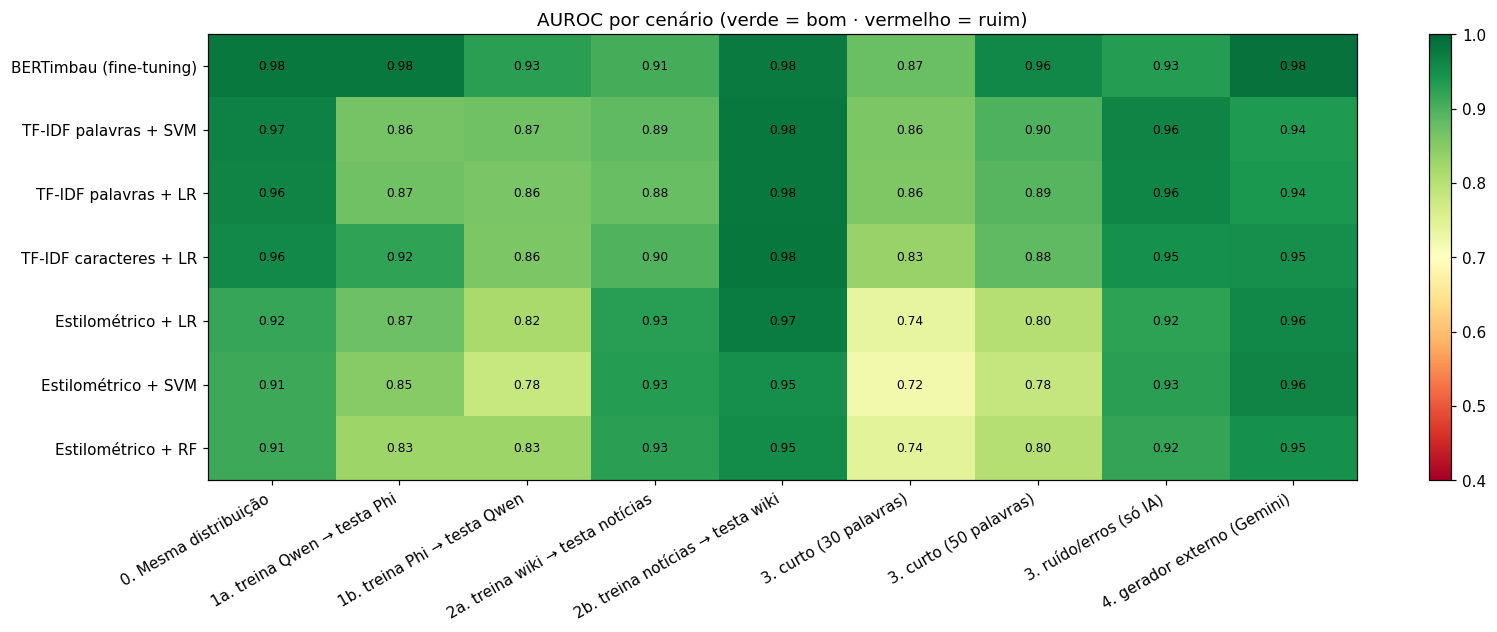

F1 por cenário (limiar 0,5):


experimento,0. Mesma distribuição,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki,3. curto (30 palavras),3. curto (50 palavras),3. ruído/erros (só IA),4. gerador externo (Gemini)
detector,,,,,,,,,
BERTimbau (fine-tuning),0.926,0.951,0.838,0.812,0.940,0.804,0.890,0.872,0.937
TF-IDF palavras + SVM,0.881,0.719,0.722,0.789,0.924,0.703,0.809,0.887,0.839
TF-IDF palavras + LR,0.895,0.758,0.712,0.788,0.923,0.712,0.807,0.901,0.852
TF-IDF caracteres + LR,0.875,0.854,0.795,0.818,0.931,0.393,0.716,0.863,0.845
Estilométrico + LR,0.856,0.590,0.676,0.846,0.905,0.711,0.713,0.862,0.898
Estilométrico + SVM,0.821,0.658,0.623,0.847,0.874,0.707,0.745,0.834,0.897
Estilométrico + RF,0.844,0.514,0.754,0.841,0.885,0.667,0.723,0.851,0.870


**Resumo (PQ3, AUROC):**

- **Entre geradores:** queda média de AUROC de **-0.078**; o mais robusto foi **BERTimbau (fine-tuning)** (-0.025) e o menos robusto **TF-IDF palavras + SVM** (-0.099).
- **Entre domínios:** queda média de **-0.006**.
- **Estresse (texto curto/ruído):** queda média de **-0.076**.
- **Gerador externo (Gemini):** AUROC médio de **0.954** (queda +0.011); melhor detector neste cenário: **BERTimbau (fine-tuning)** (0.985).
- Pior cenário no geral: **3. curto (30 palavras)** (queda média -0.141).

Uma queda grande indica que o detector aprendeu características do gerador ou do domínio de treino. A 11.6 mostra o FPR desses cenários e a 11.7 separa o efeito da troca do efeito do treino menor.

In [ ]:
res = pd.DataFrame(RESULTS); res.to_csv(os.path.join(PROJ, "data", "resultados_robustez.csv"), index=False)
piv_all = res.pivot(index="detector", columns="experimento", values="auroc").loc[tab_id.index].round(3)
ctrl_cols = [c for c in piv_all.columns if c.startswith("5")]
piv = piv_all.drop(columns=ctrl_cols)
display(piv)

def heatmap(p, title, vmin=0.4, vmax=1.0, cmap="RdYlGn", fmt="{:.2f}"):
    fig, ax = plt.subplots(figsize=(1.35 * len(p.columns) + 3, 0.55 * len(p) + 2))
    im = ax.imshow(p.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(p.columns)), p.columns, rotation=30, ha="right"); ax.set_yticks(range(len(p)), p.index)
    for i in range(p.shape[0]):
        for j in range(p.shape[1]): ax.text(j, i, fmt.format(p.values[i, j]), ha="center", va="center", fontsize=8)
    plt.colorbar(im); ax.set_title(title); plt.tight_layout()
heatmap(piv, "AUROC por cenário (verde = bom · vermelho = ruim)"); savefig("heatmap_auroc"); plt.show()

print("F1 por cenário (limiar 0,5):")
display(res.pivot(index="detector", columns="experimento", values="f1").loc[tab_id.index].drop(columns=ctrl_cols).round(3))

base_col = "0. Mesma distribuição"
queda = piv.sub(piv[base_col], axis=0).drop(columns=base_col)
gen_cols = [c for c in piv.columns if c.startswith("1")]; dom_cols = [c for c in piv.columns if c.startswith("2")]
str_cols = [c for c in piv.columns if c.startswith("3")]; ext_cols = [c for c in piv.columns if c.startswith("4")]
rob_gen = queda[gen_cols].mean(axis=1).sort_values(ascending=False)
linhas = [f"- **Entre geradores:** queda média de AUROC de **{queda[gen_cols].mean().mean():+.3f}**; o mais robusto foi **{rob_gen.index[0]}** ({rob_gen.iloc[0]:+.3f}) "
          f"e o menos robusto **{rob_gen.index[-1]}** ({rob_gen.iloc[-1]:+.3f}).",
          f"- **Entre domínios:** queda média de **{queda[dom_cols].mean().mean():+.3f}**.",
          f"- **Estresse (texto curto/ruído):** queda média de **{queda[str_cols].mean().mean():+.3f}**."]
if ext_cols:
    e = piv[ext_cols[0]].sort_values(ascending=False)
    linhas.append(f"- **Gerador externo (Gemini):** AUROC médio de **{e.mean():.3f}** (queda {queda[ext_cols[0]].mean():+.3f}); "
                  f"melhor detector neste cenário: **{e.index[0]}** ({e.iloc[0]:.3f}).")
linhas.append(f"- Pior cenário no geral: **{queda.mean().idxmin()}** (queda média {queda.mean().min():+.3f}).")
display(Markdown("**Resumo (PQ3, AUROC):**\n\n" + "\n".join(linhas) + "\n\n"
                 "Uma queda grande indica que o detector aprendeu características do gerador ou do domínio de treino. "
                 "A 11.6 mostra o FPR desses cenários e a 11.7 separa o efeito da troca do efeito do treino menor."))

experimento,0. Mesma distribuição,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki,3. curto (30 palavras),3. curto (50 palavras),3. ruído/erros (só IA),4. gerador externo (Gemini)
detector,,,,,,,,,
BERTimbau (fine-tuning),0.122,0.059,0.103,0.341,0.079,0.222,0.178,0.122,0.122
TF-IDF palavras + SVM,0.200,0.118,0.179,0.156,0.122,0.189,0.211,0.200,0.200
TF-IDF palavras + LR,0.167,0.157,0.205,0.178,0.129,0.144,0.167,0.167,0.167
TF-IDF caracteres + LR,0.200,0.078,0.128,0.206,0.061,0.044,0.056,0.200,0.200
Estilométrico + LR,0.144,0.078,0.154,0.256,0.050,0.711,0.644,0.144,0.144
Estilométrico + SVM,0.133,0.039,0.077,0.234,0.039,0.322,0.367,0.133,0.133
Estilométrico + RF,0.156,0.020,0.103,0.278,0.057,0.422,0.356,0.156,0.156


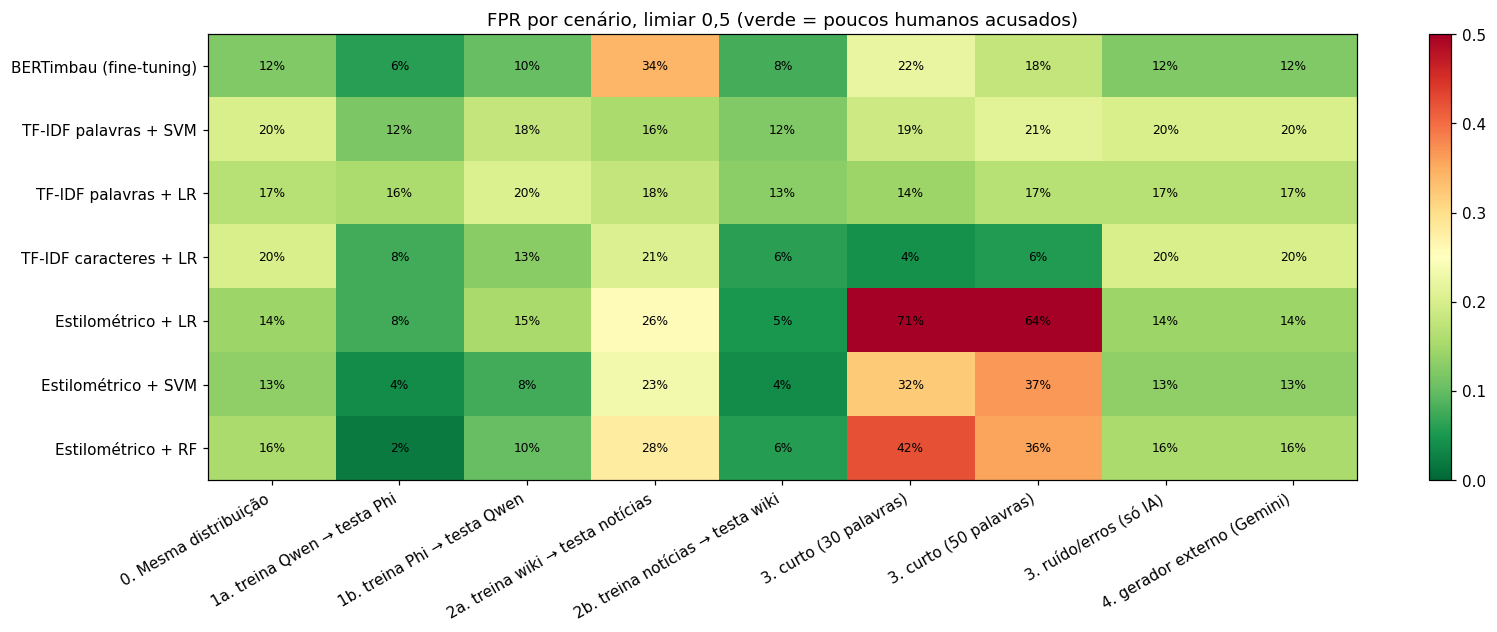

Maior FPR de cada cenário:


,detector,FPR,AUROC do mesmo detector
experimento,,,
0. Mesma distribuição,TF-IDF palavras + SVM,0.200,0.967
1a. treina Qwen → testa Phi,TF-IDF palavras + LR,0.157,0.870
1b. treina Phi → testa Qwen,TF-IDF palavras + LR,0.205,0.861
2a. treina wiki → testa notícias,BERTimbau (fine-tuning),0.341,0.905
2b. treina notícias → testa wiki,TF-IDF palavras + LR,0.129,0.977
3. curto (30 palavras),Estilométrico + LR,0.711,0.736
3. curto (50 palavras),Estilométrico + LR,0.644,0.802
3. ruído/erros (só IA),TF-IDF palavras + SVM,0.200,0.963
4. gerador externo (Gemini),TF-IDF palavras + SVM,0.200,0.936


**Resumo (FPR):** maior FPR de cada cenário: 0. Mesma distribuição: TF-IDF palavras + SVM (20.0%); 1a. treina Qwen → testa Phi: TF-IDF palavras + LR (15.7%); 1b. treina Phi → testa Qwen: TF-IDF palavras + LR (20.5%); 2a. treina wiki → testa notícias: BERTimbau (fine-tuning) (34.1%); 2b. treina notícias → testa wiki: TF-IDF palavras + LR (12.9%); 3. curto (30 palavras): Estilométrico + LR (71.1%); 3. curto (50 palavras): Estilométrico + LR (64.4%); 3. ruído/erros (só IA): TF-IDF palavras + SVM (20.0%); 4. gerador externo (Gemini): TF-IDF palavras + SVM (20.0%).

Casos com AUROC >= 0,9 e FPR >= 20%: TF-IDF palavras + SVM em '0. Mesma distribuição' (AUROC 0.967, FPR 20.0%); TF-IDF caracteres + LR em '0. Mesma distribuição' (AUROC 0.957, FPR 20.0%); BERTimbau (fine-tuning) em '2a. treina wiki → testa notícias' (AUROC 0.905, FPR 34.1%); Estilométrico + LR em '2a. treina wiki → testa notícias' (AUROC 0.928, FPR 25.6%); Estilométrico + SVM em '2a. treina wiki → testa notícias' (AUROC 0.930, FPR 23.4%); Estilométrico + RF em '2a. treina wiki → testa notícias' (AUROC 0.926, FPR 27.8%); TF-IDF palavras + SVM em '3. ruído/erros (só IA)' (AUROC 0.963, FPR 20.0%); TF-IDF caracteres + LR em '3. ruído/erros (só IA)' (AUROC 0.947, FPR 20.0%); TF-IDF palavras + SVM em '4. gerador externo (Gemini)' (AUROC 0.936, FPR 20.0%); TF-IDF caracteres + LR em '4. gerador externo (Gemini)' (AUROC 0.950, FPR 20.0%). Nesses casos o detector continua ordenando bem os textos, mas o limiar 0,5 deixa de valer fora das condições de treino, e cada falso positivo é um texto humano acusado de ser IA.

In [ ]:
fpr_tab = res.pivot_table(index="detector", columns="experimento", values="fpr").loc[tab_id.index].drop(columns=ctrl_cols).round(3)
display(fpr_tab)
heatmap(fpr_tab, "FPR por cenário, limiar 0,5 (verde = poucos humanos acusados)", vmin=0, vmax=0.5, cmap="RdYlGn_r", fmt="{:.0%}")
savefig("heatmap_fpr"); plt.show()

MAIOR_FPR = pd.DataFrame({"detector": fpr_tab.idxmax(), "FPR": fpr_tab.max()})
MAIOR_FPR["AUROC do mesmo detector"] = [piv.loc[d, c] for c, d in MAIOR_FPR.detector.items()]
print("Maior FPR de cada cenário:"); display(MAIOR_FPR.round(3))

alerta = [(d, c) for c in fpr_tab.columns for d in fpr_tab.index if piv.loc[d, c] >= 0.9 and fpr_tab.loc[d, c] >= 0.2]
itens_fpr = [f"{c}: {r.detector} ({r.FPR:.1%})" for c, r in MAIOR_FPR.iterrows()]
itens_alerta = [f"{d} em '{c}' (AUROC {piv.loc[d, c]:.3f}, FPR {fpr_tab.loc[d, c]:.1%})" for d, c in alerta]
txt_alerta = ("Casos com AUROC >= 0,9 e FPR >= 20%: " + "; ".join(itens_alerta) + ". Nesses casos o detector continua ordenando bem os textos, "
              "mas o limiar 0,5 deixa de valer fora das condições de treino, e cada falso positivo é um texto humano acusado de ser IA."
              if alerta else "Nenhum detector combina AUROC >= 0,9 com FPR >= 20%.")
display(Markdown("**Resumo (FPR):** maior FPR de cada cenário: " + "; ".join(itens_fpr) + ".\n\n" + txt_alerta))

In [ ]:
pares_ctrl = [("5a. controle: treina Qwen → testa Qwen", "1a. treina Qwen → testa Phi", "gerador"),
              ("5b. controle: treina Phi → testa Phi", "1b. treina Phi → testa Qwen", "gerador"),
              ("5c. controle: treina wiki → testa wiki", "2a. treina wiki → testa notícias", "domínio"),
              ("5d. controle: treina notícias → testa notícias", "2b. treina notícias → testa wiki", "domínio")]
base_auc = piv_all["0. Mesma distribuição"]; linhas_ctrl = []
for ctrl, exp, tipo in pares_ctrl:
    for d in piv_all.index:
        linhas_ctrl.append({"troca": tipo, "experimento": exp, "detector": d,
                            "AUROC 0": base_auc[d], "AUROC controle": piv_all.loc[d, ctrl], "AUROC experimento": piv_all.loc[d, exp],
                            "Δ treino menor": piv_all.loc[d, ctrl] - base_auc[d],
                            "Δ troca": piv_all.loc[d, exp] - piv_all.loc[d, ctrl]})
tab_ctrl = pd.DataFrame(linhas_ctrl)
tab_ctrl.round(4).to_csv(os.path.join(PROJ, "data", "controles_tamanho_treino.csv"), index=False)
display(tab_ctrl.pivot_table(index="detector", columns="experimento", values="Δ troca").loc[tab_id.index].round(3))

resumo_ctrl = tab_ctrl.groupby("experimento")[["Δ treino menor", "Δ troca"]].mean()
itens_ctrl = [f"- **{exp}:** variação total {r['Δ treino menor'] + r['Δ troca']:+.3f} = treino menor {r['Δ treino menor']:+.3f} + troca {r['Δ troca']:+.3f}"
              for exp, r in resumo_ctrl.iterrows()]
display(Markdown("**Resumo (média dos 7 detectores, AUROC):**\n\n" + "\n".join(itens_ctrl) +
                 "\n\nOs testes dos controles são pequenos, então diferenças pequenas podem vir só do sorteio dos temas."))

experimento,1a. treina Qwen → testa Phi,1b. treina Phi → testa Qwen,2a. treina wiki → testa notícias,2b. treina notícias → testa wiki
detector,,,,
BERTimbau (fine-tuning),-0.001,-0.057,-0.095,0.010
TF-IDF palavras + SVM,-0.094,-0.102,-0.099,0.023
TF-IDF palavras + LR,-0.087,-0.109,-0.105,0.025
TF-IDF caracteres + LR,-0.003,-0.116,-0.075,0.044
Estilométrico + LR,-0.087,-0.142,-0.022,0.092
Estilométrico + SVM,-0.103,-0.170,-0.008,0.055
Estilométrico + RF,-0.093,-0.108,-0.002,0.080


**Resumo (média dos 7 detectores, AUROC):**

- **1a. treina Qwen → testa Phi:** variação total -0.060 = treino menor +0.006 + troca -0.067
- **1b. treina Phi → testa Qwen:** variação total -0.095 = treino menor +0.020 + troca -0.115
- **2a. treina wiki → testa notícias:** variação total -0.037 = treino menor +0.021 + troca -0.058
- **2b. treina notícias → testa wiki:** variação total +0.026 = treino menor -0.021 + troca +0.047

Os testes dos controles são pequenos, então diferenças pequenas podem vir só do sorteio dos temas.

---
# Etapa 12 · Análise de erros e interpretabilidade

**Objetivo:** entender **onde** o melhor modelo erra e **por quê**. Os falsos positivos (humano marcado como IA) vêm primeiro, porque são o erro mais grave.

In [ ]:
_, _, test_df = get_splits(); p = ID_PROBS[BERT_NAME]; t = test_df.assign(p=p)
print("FPR por domínio (humano marcado como IA):"); display(t[t.label == 0].groupby("domain").p.apply(lambda s: (s >= .5).mean()).round(3).to_frame("FPR"))
print("Recall por gerador e domínio (IA detectada):"); display(t[t.label == 1].groupby(["source", "domain"]).p.apply(lambda s: (s >= .5).mean()).unstack().round(3))
print("\n===== Humanos com MAIOR p(IA): falsos positivos =====")
for _, r in t[t.label == 0].sort_values("p", ascending=False).head(3).iterrows(): print(f"[{r.domain}] p(IA)={r.p:.3f}\n{r.text}\n")
print("===== IA com MENOR p(IA): falsos negativos =====")
for _, r in t[t.label == 1].sort_values("p").head(3).iterrows(): print(f"[{r.source}/{r.domain}] p(IA)={r.p:.3f}\n{r.text}\n")

FPR por domínio (humano marcado como IA):


,FPR
domain,
noticias,0.149
wiki,0.093


Recall por gerador e domínio (IA detectada):


domain,noticias,wiki
source,,
phi,1.000,0.955
qwen,0.889,1.000



===== Humanos com MAIOR p(IA): falsos positivos =====
[noticias] p(IA)=0.997
Este ano, uma tendência notável é a mudança para plataformas digitais, especialmente aplicativos de apostas, como a principal ferramenta para fazer apostas. O papel dos aplicativos de apostas no aprimoramento da experiência do usuário não pode ser exagerado. Esses aplicativos transformaram a maneira como os apostadores interagem com seus esportes favoritos, oferecendo uma plataforma perfeita, intuitiva e envolvente. A conveniência de fazer apostas de qualquer lugar, a qualquer momento, repercutiu bem entre os usuários, impulsionando as tendências em 2024. A integração de atualizações ao vivo, opções de apostas em jogo e probabilidades em tempo real elevou a experiência de apostas

[noticias] p(IA)=0.997
A Polícia Rodoviária Federal (PRF) lançou, durante a Semana Nacional de Trânsito 2021, o Atlas da Década de Ações para Segurança Viária. O objetivo principal do atlas é apresentar os resultados das ações adota

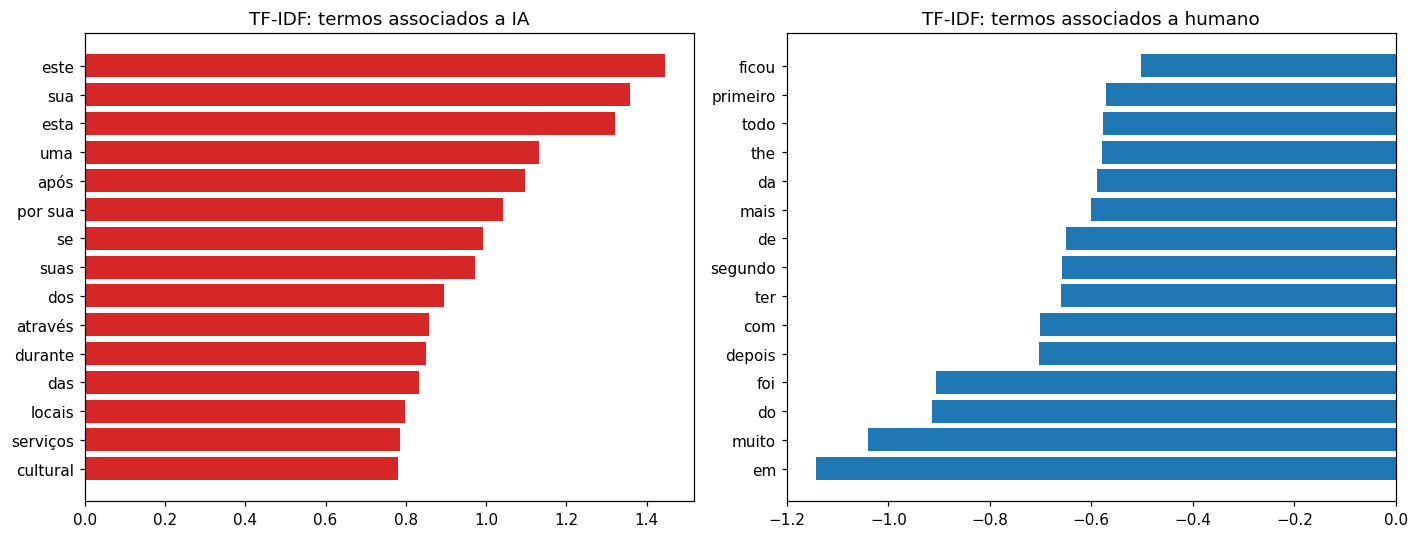

**Resumo:** verifique se os termos mais fortes são **estilo** (conectivos, fórmulas de ênfase) ou **conteúdo/domínio** (nomes próprios, termos típicos da Wikipedia ou de notícias). Termos de conteúdo explicam a queda de desempenho entre domínios na Etapa 11. A 12.3 faz essa classificação.

In [ ]:
steps = ID_DETECTORS["TF-IDF palavras + LR"].model.steps; vec, clf = steps[0][1], steps[-1][1]
names = np.array(vec.get_feature_names_out()); coef = clf.coef_[0]; ia_i, h_i = np.argsort(coef)[-15:], np.argsort(coef)[:15]
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].barh(names[ia_i], coef[ia_i], color="tab:red"); ax[0].set_title("TF-IDF: termos associados a IA")
ax[1].barh(names[h_i], coef[h_i], color="tab:blue"); ax[1].set_title("TF-IDF: termos associados a humano")
plt.tight_layout(); savefig("tfidf_termos"); plt.show()
display(Markdown("**Resumo:** verifique se os termos mais fortes são **estilo** (conectivos, fórmulas de ênfase) ou **conteúdo/domínio** "
                 "(nomes próprios, termos típicos da Wikipedia ou de notícias). Termos de conteúdo explicam a queda de desempenho entre domínios na Etapa 11. A 12.3 faz essa classificação."))

In [ ]:
LEX_ESTILO = set(CONNECTIVES) | set(stylometry.EMPHASIS)

def perfil_termo(termo, textos):
    rx = re.compile(r"\b" + re.escape(termo) + r"\b", re.I); n = n_mai = 0
    for t in textos:
        for m_ in rx.finditer(t):
            antes = t[:m_.start()].rstrip()
            if antes == "" or antes.endswith((".", "!", "?", ":")): continue
            n += 1; n_mai += m_.group(0)[0].isupper()
    return n, (n_mai / n if n else np.nan)

def categoria(termo, frac_mai):
    if any(ch.isdigit() for ch in termo): return "número ou data"
    if termo in LEX_ESTILO: return "conectivo ou ênfase"
    if frac_mai >= 0.5: return "nome próprio ou sigla"
    if all(w in STOP_PT for w in termo.split()): return "palavra funcional"
    return "outra palavra"

linhas_t = []
for idx, classe in [(ia_i, "IA"), (h_i, "humano")]:
    for k in idx:
        n_oc, fm = perfil_termo(names[k], df.text)
        linhas_t.append({"classe": classe, "termo": names[k], "coef": coef[k], "ocorrências fora do início de frase": n_oc,
                         "% com maiúscula": fm, "categoria": categoria(names[k], fm)})
tab_termos = pd.DataFrame(linhas_t)
display(tab_termos.round(3))
display(pd.crosstab(tab_termos.categoria, tab_termos.classe))

def maiusculas_internas(t):
    ws = t.split(); n = 0
    for i, w in enumerate(ws):
        if i > 0 and not ws[i - 1].endswith((".", "!", "?", ":")) and w.lstrip("\"'(")[:1].isupper(): n += 1
    return 100 * n / max(len(ws), 1)
mai_int = df.text.map(maiusculas_internas)
d_mai, _ = cliff(mai_int[df.label == 1].values, mai_int[df.label == 0].values)
n_conteudo = int(tab_termos.categoria.isin(["nome próprio ou sigla", "número ou data"]).sum())
n_estilo = int((tab_termos.categoria == "conectivo ou ênfase").sum())
display(Markdown(f"**Resumo:** maiúsculas fora do início de frase por 100 palavras: mediana {mai_int[df.label == 0].median():.1f} nos humanos e "
                 f"{mai_int[df.label == 1].median():.1f} na IA (δ de Cliff = {d_mai:.2f}). Entre os {len(tab_termos)} termos mais fortes do TF-IDF, "
                 f"{n_conteudo} são nomes próprios, siglas, números ou datas e {n_estilo} são conectivos ou marcadores de ênfase. "
                 "Diferenças em maiúsculas, dígitos e aspas indicam especificidade de conteúdo (os humanos citam fatos, nomes e datas), "
                 "não só estilo; a 14.2 deve separar as duas coisas."))

,classe,termo,coef,ocorrências fora do início de frase,% com maiúscula,categoria
0,IA,cultural,0.781,65,0.015,outra palavra
1,IA,serviços,0.784,63,0.048,outra palavra
2,IA,locais,0.797,64,0.000,outra palavra
3,IA,das,0.833,447,0.004,palavra funcional
4,IA,durante,0.849,165,0.000,outra palavra
5,IA,através,0.857,93,0.000,outra palavra
6,IA,dos,0.894,690,0.001,palavra funcional
7,IA,suas,0.972,177,0.000,palavra funcional
8,IA,se,0.991,833,0.005,palavra funcional
9,IA,por sua,1.041,92,0.000,palavra funcional


classe,IA,humano
categoria,,
nome próprio ou sigla,0,1
outra palavra,6,7
palavra funcional,9,7


**Resumo:** maiúsculas fora do início de frase por 100 palavras: mediana 14.0 nos humanos e 6.0 na IA (δ de Cliff = -0.55). Entre os 30 termos mais fortes do TF-IDF, 1 são nomes próprios, siglas, números ou datas e 0 são conectivos ou marcadores de ênfase. Diferenças em maiúsculas, dígitos e aspas indicam especificidade de conteúdo (os humanos citam fatos, nomes e datas), não só estilo; a 14.2 deve separar as duas coisas.

In [ ]:
_, _, test_df = get_splits()
def janela(t, ini, fim): return " ".join(t.split()[ini:fim])
TRECHOS = {"palavras 1-80": (0, 80), "palavras 21-100": (20, 100)}
rows_c4 = []
for nome, (ini, fim) in TRECHOS.items():
    d = test_df.copy(); d["text"] = [janela(t, ini, fim) for t in d.text]; d[FEATURE_COLS] = build_features(d.text).values
    for n, det in ID_DETECTORS.items():
        pr = det.predict_proba(d)
        for dom in ("todos",) + tuple(DOMAINS):
            m = np.ones(len(d), bool) if dom == "todos" else (d.domain == dom).values
            rows_c4.append({"trecho": nome, "domínio": dom, "detector": n, **evaluate(d.label.values[m], pr[m])})
tab_c4 = pd.DataFrame(rows_c4)
piv_c4 = tab_c4.pivot_table(index=["domínio", "detector"], columns="trecho", values="auroc")
piv_c4["diferença (21-100 menos 1-80)"] = piv_c4["palavras 21-100"] - piv_c4["palavras 1-80"]
display(piv_c4.round(3))
dif_dom = piv_c4["diferença (21-100 menos 1-80)"].groupby(level="domínio").mean()
display(Markdown("**Resumo:** variação média do AUROC ao tirar as 20 primeiras palavras: "
                 + "; ".join(f"{dom}: {v:+.3f}" for dom, v in dif_dom.items())
                 + ". Uma queda maior nas notícias que na Wikipedia indicaria que parte do sinal vem da repetição da manchete no início do texto de IA."))

trecho                            palavras 1-80  palavras 21-100  \
domínio  detector                                                  
noticias BERTimbau (fine-tuning)          0.963            0.952   
         Estilométrico + LR               0.849            0.908   
         Estilométrico + RF               0.859            0.884   
         Estilométrico + SVM              0.858            0.892   
         TF-IDF caracteres + LR           0.912            0.932   
         TF-IDF palavras + LR             0.924            0.939   
         TF-IDF palavras + SVM            0.930            0.943   
todos    BERTimbau (fine-tuning)          0.969            0.971   
         Estilométrico + LR               0.881            0.924   
         Estilométrico + RF               0.872            0.898   
         Estilométrico + SVM              0.884            0.908   
         TF-IDF caracteres + LR           0.943            0.955   
         TF-IDF palavras + LR             0.953            0.956   
         TF-IDF palavras + SVM            0.957            0.956   
wiki     BERTimbau (fine-tuning)          0.984            0.988   
         Estilométrico + LR               0.913            0.945   
         Estilométrico + RF               0.889            0.909   
         Estilométrico + SVM              0.909            0.922   
         TF-IDF caracteres + LR           0.969            0.977   
         TF-IDF palavras + LR             0.978            0.975   
         TF-IDF palavras + SVM            0.983            0.975   

trecho                            diferença (21-100 menos 1-80)  
domínio  detector                                                
noticias BERTimbau (fine-tuning)                         -0.010  
         Estilométrico + LR                               0.059  
         Estilométrico + RF                               0.025  
         Estilométrico + SVM                              0.033  
         TF-IDF caracteres + LR                           0.020  
         TF-IDF palavras + LR                             0.015  
         TF-IDF palavras + SVM                            0.013  
todos    BERTimbau (fine-tuning)                          0.002  
         Estilométrico + LR                               0.043  
         Estilométrico + RF                               0.026  
         Estilométrico + SVM                              0.024  
         TF-IDF caracteres + LR                           0.012  
         TF-IDF palavras + LR                             0.003  
         TF-IDF palavras + SVM                           -0.001  
wiki     BERTimbau (fine-tuning)                          0.003  
         Estilométrico + LR                               0.031  
         Estilométrico + RF                               0.020  
         Estilométrico + SVM                              0.014  
         TF-IDF caracteres + LR                           0.008  
         TF-IDF palavras + LR                            -0.003  
         TF-IDF palavras + SVM                           -0.008

**Resumo:** variação média do AUROC ao tirar as 20 primeiras palavras: noticias: +0.022; todos: +0.016; wiki: +0.009. Uma queda maior nas notícias que na Wikipedia indicaria que parte do sinal vem da repetição da manchete no início do texto de IA.

---
# Etapa 13 · Plataforma de análise de autoria (Projeto Integrador)

**Objetivo:** levar o que foi treinado aqui ao usuário final. A plataforma (`app.py`, em **Gradio**) recebe um texto e mostra:

| Requisito (8.5) | Como aparece no app |
|---|---|
| Classificação humano/IA | Veredito em três faixas: provavelmente humano (P(IA) ≤ 0,35) · inconclusivo · provavelmente IA (limiar escolhido na validação, 13.2) |
| Probabilidade estimada | P(IA) combinada (média dos dois modelos) |
| Indicadores estilométricos | Tabela com o valor do texto e as médias de humanos e de IA do treino |
| Resultado do modelo clássico | Linha própria na tabela de resultados por modelo |
| Resultado do Transformer | Linha própria (BERTimbau) |
| Visualizações | Gráfico de posição do texto entre a média humana e a média de IA nos 10 indicadores mais discriminativos |
| Aviso de estimativa experimental | Fixo no topo da página e repetido junto ao resultado |

Textos longos são divididos em trechos de 100 palavras (tamanho do treino) e as probabilidades são a média dos trechos; textos curtos recebem aviso de baixa confiabilidade; se os dois modelos discordarem fortemente, o app avisa.

In [ ]:
%%writefile app.py
"""
app.py - Plataforma de análise de autoria textual (humano vs. IA)

Projeto: Humano ou IA? Identificação de autoria textual em português (FATEC Jundiaí)
Autores: Allan Vytor Francisco Oliveira, Gabriel Passos, Guilherme Tenório Cavalcante

Execução:  python app.py   ->   http://127.0.0.1:7860
Requer, na mesma pasta: stylometry.py e a pasta models/ exportada pelo notebook.
"""
import json
import os

import gradio as gr
import joblib
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

from stylometry import FEATURE_COLS, FEATURE_LABELS, TRUNC_WORDS, build_features, n_words, preprocess, windows

BASE = os.path.dirname(os.path.abspath(__file__))
MODELS = os.path.join(BASE, "models")

META = json.load(open(os.path.join(MODELS, "meta.json"), encoding="utf-8"))
REF = json.load(open(os.path.join(MODELS, "reference_stats.json"), encoding="utf-8"))
CLS = joblib.load(os.path.join(MODELS, "classico.joblib"))
TOK = AutoTokenizer.from_pretrained(os.path.join(MODELS, "bertimbau"))
BERT = AutoModelForSequenceClassification.from_pretrained(os.path.join(MODELS, "bertimbau")).eval()
MAX_LEN = META.get("bert_max_len", 192)
T_HUMAN, T_AI = META["thresholds"]["human_max"], META["thresholds"]["ai_min"]
MIN_WORDS_WARN = 50

AVISO = ("**Estimativa experimental, não prova de autoria.** Os modelos foram treinados com trechos de cerca de "
         f"{TRUNC_WORDS} palavras em português (Wikipedia e notícias) e com textos de dois modelos de linguagem abertos. "
         "O resultado é uma probabilidade estatística que pode errar, inclusive marcando como IA um texto escrito por "
         "uma pessoa. Não use este resultado para acusar ou punir ninguém.")


def prob_classico(chunks):
    if CLS["kind"] == "text":
        p = CLS["model"].predict_proba(chunks)[:, 1]
    else:
        p = CLS["model"].predict_proba(build_features(chunks)[CLS["cols"]])[:, 1]
    return float(np.mean(p))


@torch.no_grad()
def prob_bert(chunks):
    enc = TOK(chunks, truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")
    p = torch.softmax(BERT(**enc).logits, -1)[:, 1].numpy()
    return float(np.mean(p))


def veredito(p):
    if p >= T_AI:
        return "Provavelmente gerado por IA"
    if p <= T_HUMAN:
        return "Provavelmente escrito por humano"
    return "Inconclusivo"


def indicadores(chunks):
    f = build_features(chunks).mean()
    rows = []
    for c in FEATURE_COLS:
        r, v = REF[c], float(f[c])
        d_h = abs(v - r["human_mean"]) / (r["human_std"] + 1e-9)
        d_a = abs(v - r["ai_mean"]) / (r["ai_std"] + 1e-9)
        rows.append({"Indicador": FEATURE_LABELS[c], "Este texto": v, "Média humanos": r["human_mean"],
                     "Média IA": r["ai_mean"], "Mais próximo de": "IA" if d_a < d_h else "Humano", "effect": r["effect"]})
    return pd.DataFrame(rows)


def grafico(tab, k=10):
    top = tab.reindex(tab["effect"].abs().sort_values(ascending=False).index).head(k)
    pos = [(r["Este texto"] - r["Média humanos"]) / (r["Média IA"] - r["Média humanos"])
           if abs(r["Média IA"] - r["Média humanos"]) > 1e-9 else 0.5 for _, r in top.iterrows()]
    pos = np.clip(pos, -1, 2)
    y = np.arange(len(top))[::-1]
    fig, ax = plt.subplots(figsize=(7.5, 4.8))
    ax.axvspan(-1.05, 0.5, color="#2471a3", alpha=0.06)
    ax.axvspan(0.5, 2.05, color="#c0392b", alpha=0.06)
    ax.axvline(0, color="#2471a3", ls="--", lw=1.2, label="média dos humanos")
    ax.axvline(1, color="#c0392b", ls="--", lw=1.2, label="média da IA")
    ax.scatter(pos, y, s=70, color="#222", zorder=3, label="este texto")
    ax.set_yticks(y, top["Indicador"], fontsize=8)
    ax.set_xlim(-1.05, 2.05)
    ax.set_xlabel("Posição relativa (0 = média humana · 1 = média da IA)")
    ax.set_title("Os 10 indicadores que mais separam humano e IA")
    ax.legend(fontsize=7, loc="lower right")
    plt.tight_layout()
    return fig


def analisar(texto):
    t = preprocess(texto or "")
    nw = n_words(t)
    if nw < 10:
        return "Cole um texto em português com pelo menos algumas frases.", None, None, None, None
    chunks = windows(t, TRUNC_WORDS, min_last=50)
    pc, pb = prob_classico(chunks), prob_bert(chunks)
    pm = (pc + pb) / 2

    avisos = []
    if nw < MIN_WORDS_WARN:
        avisos.append(f"Texto curto ({nw} palavras): a confiabilidade é baixa. O ideal é ter {TRUNC_WORDS} palavras ou mais.")
    if len(chunks) > 1:
        avisos.append(f"Texto dividido em {len(chunks)} trechos de ~{TRUNC_WORDS} palavras; as probabilidades são a média dos trechos.")
    if abs(pc - pb) > 0.4:
        avisos.append("Os dois modelos discordam fortemente: trate o resultado como inconclusivo.")

    resumo = (f"## {veredito(pm)}\n**Probabilidade estimada de IA (média dos dois modelos): {pm:.0%}**\n\n"
              + "".join(f"- {a}\n" for a in avisos) + "\n" + AVISO)
    modelos = pd.DataFrame([
        {"Modelo": f"Clássico: {CLS['name']}", "P(IA)": f"{pc:.1%}", "Classificação": veredito(pc)},
        {"Modelo": "Transformer: BERTimbau (fine-tuning)", "P(IA)": f"{pb:.1%}", "Classificação": veredito(pb)},
    ])
    tab = indicadores(chunks)
    fig = grafico(tab)
    tab_show = tab.drop(columns="effect").round(3)
    return resumo, {"IA": pm, "Humano": 1 - pm}, modelos, tab_show, fig


def rodape():
    linhas = []
    for nome, m in META.get("test_metrics", {}).items():
        linhas.append(f"{nome}: AUROC {m['auroc']:.3f} · F1 {m['f1']:.3f} · FPR {m['fpr']:.1%}")
    return ("**Desempenho no conjunto de teste (mesma distribuição do treino):** " + " | ".join(linhas)
            + f"  \nModelos treinados em {META.get('criado_em', '?')}. Fora dessas condições (outros geradores, "
              "outros gêneros, textos editados por humanos) o desempenho tende a cair; veja a Etapa 11 do notebook.")


with gr.Blocks(title="Humano ou IA? · Análise de autoria") as demo:
    gr.Markdown("# Humano ou IA? Análise de autoria textual\n"
                "Projeto Integrador · FATEC Jundiaí · Allan Vytor Francisco Oliveira, Gabriel Passos e "
                "Guilherme Tenório Cavalcante\n\n" + AVISO)
    with gr.Row():
        with gr.Column(scale=3):
            entrada = gr.Textbox(lines=12, label="Texto em português", placeholder="Cole aqui o texto (ideal: 100 palavras ou mais)")
            botao = gr.Button("Analisar", variant="primary")
        with gr.Column(scale=2):
            out_resumo = gr.Markdown()
            out_prob = gr.Label(num_top_classes=2, label="Probabilidade estimada")
    out_modelos = gr.Dataframe(label="Resultado por modelo", interactive=False)
    with gr.Row():
        out_graf = gr.Plot(label="Visualização dos indicadores")
        out_tab = gr.Dataframe(label="Indicadores estilométricos", interactive=False)
    gr.Markdown(rodape())
    botao.click(analisar, inputs=entrada, outputs=[out_resumo, out_prob, out_modelos, out_tab, out_graf])

if __name__ == "__main__":
    demo.launch(server_name="127.0.0.1", server_port=7860)

Writing app.py


### 13.2 Exportação dos artefatos
Exportamos para `export/` (e para um `.zip` baixável):
- `models/classico.joblib`: o melhor modelo clássico (escolhido pelo AUROC de **validação**, não de teste);
- `models/bertimbau/`: o BERTimbau com fine-tuning (pesos + tokenizer);
- `models/reference_stats.json`: médias/desvios dos atributos por classe (para os gráficos do app);
- `models/meta.json`: versões de bibliotecas, limiares e métricas. O limiar de "provavelmente IA" é o maior entre 0,65 e o valor que deixa no máximo 5% dos humanos da validação acima dele;
- `stylometry.py` (o **mesmo** módulo do treino), `app.py`, `requirements.txt` (com as versões do treino, inclusive torch e gradio) e `README.md`.

O dataset não vai no pacote: o `app.py` não usa esse arquivo (ver 2.0).

In [ ]:
EXPORT = os.path.join(PROJ, "export"); MODELS_DIR = os.path.join(EXPORT, "models")
shutil.rmtree(EXPORT, ignore_errors=True); os.makedirs(os.path.join(MODELS_DIR, "bertimbau"))
_, _, test_df = get_splits()

best_classico = max(CLASSICAL, key=lambda n: ID_VAL_AUC[n]); det = ID_DETECTORS[best_classico]

_, val_df, _ = get_splits()
pm_val = (ID_DETECTORS[best_classico].predict_proba(val_df) + ID_DETECTORS[BERT_NAME].predict_proba(val_df)) / 2
AI_MIN = max(0.65, float(np.quantile(pm_val[val_df.label.values == 0], 0.95)))
pm_test = (ID_PROBS[best_classico] + ID_PROBS[BERT_NAME]) / 2
print(f"Limiar 'provavelmente IA': {AI_MIN:.3f}")
for nome_, d_, pm_ in [("validação", val_df, pm_val), ("teste", test_df, pm_test)]:
    h_, a_ = pm_[d_.label.values == 0], pm_[d_.label.values == 1]
    print(f"  {nome_}: humanos acima do limiar = {(h_ >= AI_MIN).mean():.1%} (com 0,65: {(h_ >= 0.65).mean():.1%}) | IA acima = {(a_ >= AI_MIN).mean():.1%}")
joblib.dump({"name": best_classico, "kind": "text" if det.cols is None else "features", "cols": det.cols, "model": det.model},
            os.path.join(MODELS_DIR, "classico.joblib"))
bert = ID_DETECTORS[BERT_NAME]; bert.model.save_pretrained(os.path.join(MODELS_DIR, "bertimbau")); bert.tok.save_pretrained(os.path.join(MODELS_DIR, "bertimbau"))

tr = df[df.split == "train"]; ref = {}
for c in FEATURE_COLS:
    h, a = tr.loc[tr.label == 0, c], tr.loc[tr.label == 1, c]; sd = np.sqrt((h.var() + a.var()) / 2) + 1e-9
    ref[c] = {"human_mean": float(h.mean()), "human_std": float(h.std()), "ai_mean": float(a.mean()), "ai_std": float(a.std()), "effect": float((a.mean() - h.mean()) / sd)}
json.dump(ref, open(os.path.join(MODELS_DIR, "reference_stats.json"), "w"), ensure_ascii=False, indent=1)

meta = {"criado_em": datetime.now().isoformat(timespec="seconds"), "trunc_words": TRUNC_WORDS, "bert_model": BERT_MODEL, "bert_max_len": BERT_MAX_LEN,
        "thresholds": {"human_max": 0.35, "ai_min": round(AI_MIN, 4), "ai_min_origem": "max(0,65; quantil 95% de P(IA) dos humanos da validação)"}, "classico": best_classico,
        "versions": {"python": platform.python_version(), "scikit-learn": sklearn.__version__, "numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__,
                     "transformers": transformers.__version__, "joblib": joblib.__version__},
        "test_metrics": {best_classico: evaluate(test_df.label, ID_PROBS[best_classico]), BERT_NAME: evaluate(test_df.label, ID_PROBS[BERT_NAME])},
        "dataset": {"n_textos": int(len(df)), "dominios": sorted(df.domain.unique().tolist()), "geradores": GENERATORS}}
json.dump(meta, open(os.path.join(MODELS_DIR, "meta.json"), "w"), ensure_ascii=False, indent=1, default=float)

np_major = int(np.__version__.split(".")[0])
GRADIO_VERSION = None
open(os.path.join(EXPORT, "requirements.txt"), "w").write("\n".join([
    f"gradio=={GRADIO_VERSION}" if GRADIO_VERSION else "gradio>=4.44,<6", f"torch=={torch.__version__.split('+')[0]}", f"transformers=={transformers.__version__}", f"scikit-learn=={sklearn.__version__}",
    f"numpy>={np_major}.0,<{np_major + 1}", "pandas", "scipy", "matplotlib", f"joblib>={joblib.__version__}"]) + "\n")
open(os.path.join(EXPORT, "README.md"), "w", encoding="utf-8").write(
    "# Plataforma: Humano ou IA? (análise de autoria textual)\n\n"
    "Autores: Allan Vytor Francisco Oliveira, Gabriel Passos, Guilherme Tenório Cavalcante (FATEC Jundiaí)\n\n"
    "```bash\npython -m venv .venv\nsource .venv/bin/activate   # Windows: .venv\\Scripts\\activate\n"
    "pip install -r requirements.txt\npython app.py   # abre em http://127.0.0.1:7860\n```\n\n"
    "O resultado é uma estimativa experimental, não prova de autoria.\n")

for f in ["stylometry.py", "app.py"]: shutil.copy(f, os.path.join(EXPORT, f))
zip_path = shutil.make_archive(os.path.join(PROJ, "artefatos_plataforma"), "zip", EXPORT)
print("Modelo clássico exportado:", best_classico, "| scikit-learn:", sklearn.__version__)
print("Pacote:", zip_path, f"({os.path.getsize(zip_path)/1e6:.0f} MB)")
try:
    from google.colab import files; files.download(zip_path)
except Exception as e:
    print("Baixe o .zip pelo painel de arquivos ou pelo Google Drive.", e)

Limiar 'provavelmente IA': 0.661
  validação: humanos acima do limiar = 5.6% (com 0,65: 5.6%) | IA acima = 98.9%
  teste: humanos acima do limiar = 8.9% (com 0,65: 8.9%) | IA acima = 94.4%


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modelo clássico exportado: TF-IDF caracteres + LR | scikit-learn: 1.6.1
Pacote: /content/drive/MyDrive/auditoria_humano_ia_final/artefatos_plataforma.zip (405 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
RUN_DEMO = False
if RUN_DEMO:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"gradio=={GRADIO_VERSION}" if GRADIO_VERSION else "gradio>=4.44,<6"])
    os.chdir(EXPORT); sys.path.insert(0, EXPORT)
    import app; importlib.reload(app)
    app.demo.launch(share=True)

### 13.4 Como rodar a plataforma no VS Code
1. Descompacte `artefatos_plataforma.zip` em uma pasta `plataforma/` (ela já contém `app.py`, `stylometry.py`, `models/`, `requirements.txt` e `README.md`).
2. No terminal do VS Code, dentro dessa pasta:
   ```bash
   python -m venv .venv
   source .venv/bin/activate          # Windows: .venv\Scripts\activate
   pip install -r requirements.txt     # usa as mesmas versões do treino
   python app.py
   ```
3. Abra o endereço mostrado no terminal (normalmente `http://127.0.0.1:7860`).

Para a apresentação, também dá para usar a célula 13.3 (`RUN_DEMO = True`), que abre o app no Colab com um link público temporário.

---
# Etapa 14 · Conclusões, limitações e ética

### 14.1 Resumo gerado automaticamente a partir dos seus resultados

In [ ]:
b = tab_id.iloc[0]
cl_tab = tab_id.loc[[n for n in tab_id.index if n in CLASSICAL]]; cl_name, cl = cl_tab.index[0], cl_tab.iloc[0]
top3 = ", ".join(f"**{a}**" for a in efeitos["atributo"].head(3))
ext_txt = (f" Diante do **Gemini**, nunca visto no treino, o AUROC médio foi **{piv[ext_cols[0]].mean():.3f}** "
           f"(queda {queda[ext_cols[0]].mean():+.3f})." if ext_cols else " O teste com o gerador externo (Gemini) não foi executado.")

dif_bc = tab_dif[(tab_dif["modelo A"] == BERT_NAME) & (tab_dif["modelo B"] == best_c)]
dif_txt = ""
if len(dif_bc):
    r = dif_bc.iloc[0]
    dif_txt = (f" A diferença de AUROC entre o BERTimbau e {best_c} foi {r['AUROC A - B']:+.3f} (IC95% [{r['IC95% inf']:+.3f}, {r['IC95% sup']:+.3f}]; {r['leitura']}).")
troca = tab_ctrl.groupby("troca")["Δ troca"].mean()
fpr_itens = "; ".join(f"{c}: {r.detector} com {r.FPR:.1%}" for c, r in MAIOR_FPR.iterrows() if c != base_col)

display(Markdown(f"""
**PQ1 · Classificação.** Na mesma distribuição, o melhor modelo foi **{tab_id.index[0]}** (AUROC {b['AUROC']:.3f}, FPR {b['FPR']:.1%}), contra AUROC {m0['auroc']:.2f} da referência ingênua. Entre os clássicos, **{cl_name}** (AUROC {cl['AUROC']:.3f}). O BERTimbau obteve AUROC **{tab_id.loc[BERT_NAME,'AUROC']:.3f}** e, em {len(SEEDS_BERT)} sementes, {ms.loc['mean','auroc']:.3f} ± {ms.loc['std','auroc']:.3f}.{dif_txt}

**PQ2 · Padrões de escrita.** Os atributos que mais separam as classes: {top3}. {len(sig_w)} de {len(FEATURE_COLS)} atributos diferem no teste pareado de Wilcoxon, e {int(efeitos['consistente'].sum())} mantêm o mesmo sentido nos dois domínios. No clustering (k = 2), a estrutura não supervisionada se alinha mais a **{best_ref}**.

**PQ3 · Generalização.** Queda média de AUROC: **{queda[gen_cols].mean().mean():+.3f}** ao trocar de gerador, **{queda[dom_cols].mean().mean():+.3f}** ao trocar de domínio e **{queda[str_cols].mean().mean():+.3f}** em textos curtos/ruidosos.{ext_txt} Cenário mais difícil: **{queda.mean().idxmin()}**. Descontado o treino menor (controles 5a a 5d), a troca de gerador muda o AUROC em {troca.get('gerador', np.nan):+.3f} e a de domínio em {troca.get('domínio', np.nan):+.3f}, em média.

**PQ3 · Falsos positivos (limiar 0,5).** Maior FPR de cada cenário: {fpr_itens}. O AUROC pode continuar alto enquanto o FPR sobe: o detector ordena bem os textos, mas o limiar fixo de 0,5 deixa de valer em outro domínio ou gerador.
"""))


**PQ1 · Classificação.** Na mesma distribuição, o melhor modelo foi **BERTimbau (fine-tuning)** (AUROC 0.977, FPR 12.2%), contra AUROC 0.50 da referência ingênua. Entre os clássicos, **TF-IDF palavras + SVM** (AUROC 0.967). O BERTimbau obteve AUROC **0.977** e, em 3 sementes, 0.981 ± 0.004. A diferença de AUROC entre o BERTimbau e TF-IDF palavras + SVM foi +0.010 (IC95% [-0.012, +0.036]; IC contém 0: sem diferença clara).

**PQ2 · Padrões de escrita.** Os atributos que mais separam as classes: **Tamanho médio da palavra (letras)**, **Sílabas por palavra (aprox.)**, **Legibilidade (Flesch-PT; maior = mais fácil)**. 21 de 24 atributos diferem no teste pareado de Wilcoxon, e 21 mantêm o mesmo sentido nos dois domínios. No clustering (k = 2), a estrutura não supervisionada se alinha mais a **autoria (humano/IA)**.

**PQ3 · Generalização.** Queda média de AUROC: **-0.078** ao trocar de gerador, **-0.006** ao trocar de domínio e **-0.076** em textos curtos/ruidosos. Diante do **Gemini**, nunca visto no treino, o AUROC médio foi **0.954** (queda +0.011). Cenário mais difícil: **3. curto (30 palavras)**. Descontado o treino menor (controles 5a a 5d), a troca de gerador muda o AUROC em -0.091 e a de domínio em -0.005, em média.

**PQ3 · Falsos positivos (limiar 0,5).** Maior FPR de cada cenário: 1a. treina Qwen → testa Phi: TF-IDF palavras + LR com 15.7%; 1b. treina Phi → testa Qwen: TF-IDF palavras + LR com 20.5%; 2a. treina wiki → testa notícias: BERTimbau (fine-tuning) com 34.1%; 2b. treina notícias → testa wiki: TF-IDF palavras + LR com 12.9%; 3. curto (30 palavras): Estilométrico + LR com 71.1%; 3. curto (50 palavras): Estilométrico + LR com 64.4%; 3. ruído/erros (só IA): TF-IDF palavras + SVM com 20.0%; 4. gerador externo (Gemini): TF-IDF palavras + SVM com 20.0%. O AUROC pode continuar alto enquanto o FPR sobe: o detector ordena bem os textos, mas o limiar fixo de 0,5 deixa de valer em outro domínio ou gerador.


### 14.2 Interpretação do grupo

1. **O que funcionou.** Todos os detectores superaram com folga a referência ingênua (AUROC 0,500): no teste, a AUROC foi de 0,911 a 0,967 nos modelos clássicos e de 0,977 no BERTimbau. O TF-IDF de palavras com SVM superou a melhor estilometria por 0,049 de AUROC (IC95% de 0,016 a 0,087). O BERTimbau teve a maior AUROC, mas a diferença para o TF-IDF de palavras com SVM (+0,010; IC95% de −0,012 a 0,036) não é significativa. A vantagem dele está no FPR (12,2% contra 20,0%) e na detecção com FPR de 5% (92,2% contra 80,0%). Em três sementes, a AUROC do BERTimbau variou pouco (0,981 ± 0,004), mas o FPR foi de 6,7% a 12,2%.

2. **O que não generalizou e por quê.** Entre as trocas de condição de treino, a de gerador causou a maior perda. Descontado o treino menor (controles 5a e 5b), a AUROC cai 0,067 de Qwen para Phi e 0,115 de Phi para Qwen, em média, chegando a 0,170 na estilometria com SVM. O BERTimbau não perdeu nada de Qwen para Phi, mas perdeu 0,057 no sentido inverso. Entre domínios, o efeito depende do sentido: treinados na Wikipédia e testados em notícias, o TF-IDF e o BERTimbau perderam de 0,075 a 0,105, e a estilometria, no máximo 0,022; no sentido inverso, todos melhoraram. O pior cenário foram os textos de 30 palavras (queda média de 0,141 de AUROC). O problema mais sério é o limiar: treinado na Wikipédia, o BERTimbau manteve AUROC de 0,905 em notícias, mas marcou como IA 34,1% dos textos humanos, e com 30 palavras a RL estilométrica chegou a 71,1% de FPR. Os modelos continuam ordenando bem os textos, mas o limiar de 0,5 aprendido em uma condição não vale em outra.

3. **Atributos de estilo.** São diferenças de estilo palavras mais longas (5,48 contra 4,84 letras), menor legibilidade (Flesch 24,7 contra 49,6), mais diversidade vocabular e frases mais uniformes. As classes diferem em 21 dos 24 atributos, nos dois domínios e no teste pareado; em 93% dos temas, o texto gerado tem palavras mais longas que o humano. Maiúsculas, dígitos e aspas indicam conteúdo e especificidade: os humanos têm 14 palavras com inicial maiúscula fora do início de frase por 100 palavras, contra 6 na IA, o que reflete nomes, datas e citações. Conectivos e marcadores de ênfase não diferiram, exceto "além disso" (4,8 vezes mais frequente na IA). O TF-IDF se apoia em palavras funcionais ("este", "sua", "por sua"), não em nomes próprios.

4. **Modelo recomendado.** O BERTimbau é o recomendado: teve o menor FPR na mesma distribuição e o melhor resultado com o Gemini (AUROC 0,985, 89 dos 90 textos detectados). Os atributos estilométricos ficam como complemento, porque se transferiram melhor da Wikipédia para as notícias e são interpretáveis. Na plataforma, o BERTimbau é combinado ao TF-IDF de caracteres com RL, o clássico de maior AUROC na validação (13.2), e os 24 atributos aparecem como indicadores. Nenhum modelo deve ser usado com limiar fixo fora do domínio de treino. O teste externo usa um único gerador comercial, então o resultado com o Gemini indica uma tendência, não uma garantia para outros modelos.

### 14.3 Limitações
- **Geradores.** O treino usa dois modelos abertos pequenos (1,5B e 3,8B de parâmetros), um prompt por domínio e `temperature=0.8`. O Gemini entra só no teste, nos temas do conjunto de teste, e um único gerador externo não representa os modelos comerciais em geral.
- **Gêneros e tamanho.** Só verbetes de enciclopédia e notícias, sempre em trechos de 100 palavras. Textos curtos aparecem só no teste de estresse (11.3), e textos de IA editados por pessoas não foram testados.
- **Tamanho do teste.** O teste tem 90 pares; os intervalos de confiança (10.1 e 10.2) refletem isso, e os controles da 11.7 usam testes ainda menores.
- **Hiperparâmetros.** Não houve busca de hiperparâmetros: os modelos usam valores padrão, com pesos balanceados por classe.
- **Limpeza.** Os filtros que dependem do tamanho olham só as 100 palavras do corpus (`FILTROS_APOS_CORTE = True`). Aplicado ao texto inteiro, o filtro de repetição descartaria 39 textos humanos e 3 de IA, porque o humano bruto é mais longo (4.5b).
- **Conteúdo e estilo.** Parte do sinal vem de especificidade de conteúdo (nomes próprios, números, citações), não de estilo (12.3). Um texto de IA cheio de fatos específicos, ou um texto humano genérico, tende a ser mal classificado.
- **Notícias.** A primeira frase da notícia humana virou o prompt e saiu do texto humano, e o texto de IA pode repeti-la no início. Tirar as 20 primeiras palavras não reduziu a AUROC (12.4), então essa repetição não parece servir de atalho aos detectores.
- **Limiares da plataforma.** O limiar de "provavelmente IA" foi escolhido com 90 humanos da validação, dos dois domínios do treino. Fora deles o FPR pode ser bem maior (11.6).

### 14.4 Ética
- Um falso positivo é um texto humano acusado de ser IA. Por isso o FPR aparece em todas as tabelas e a plataforma repete o aviso de estimativa experimental junto ao resultado.
- O resultado do detector não serve como prova de autoria nem como base para punir alguém, em aula, em processo seletivo ou em publicação.
- Os textos da Wikipedia e das notícias são públicos, mas citam pessoas reais; os CSVs circulam só entre o grupo e o professor (2.0).
- A chave da API do Gemini fica nos Secrets do Colab e não aparece no notebook entregue.

In [ ]:
registro = {"data": datetime.now().isoformat(timespec="seconds"),
            "duracao_min": round((time.time() - T0_EXEC) / 60, 1),
            "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else "sem GPU",
            "quick_mode": QUICK_MODE, "dataset_bruto_em_cache": LOAD_RAW, "filtros_apos_corte": FILTROS_APOS_CORTE,
            "gemini_executado": bool(EXT_OK), "gemini_textos_por_modelo": GEMINI_MODELOS_USADOS if EXT_OK else None,
            "seed": SEED, "sementes_bertimbau": list(SEEDS_BERT), "versoes": VERSOES,
            "particoes": {s: {"humano": int(((df.split == s) & (df.label == 0)).sum()), "IA": int(((df.split == s) & (df.label == 1)).sum())}
                          for s in ("train", "val", "test")}}
json.dump(registro, open(os.path.join(PROJ, "data", "registro_execucao.json"), "w"), ensure_ascii=False, indent=2)
print(json.dumps(registro, ensure_ascii=False, indent=2))

{
  "data": "2026-11-18T23:32:08",
  "duracao_min": 31.7,
  "gpu": "Tesla T4",
  "quick_mode": false,
  "dataset_bruto_em_cache": true,
  "filtros_apos_corte": true,
  "gemini_executado": true,
  "gemini_textos_por_modelo": {
    "gemini-3.1-flash-lite": 89,
    "gemini-3.6-flash": 1
  },
  "seed": 42,
  "sementes_bertimbau": [
    42,
    7,
    2026
  ],
  "versoes": {
    "python": "3.13.16",
    "numpy": "2.4.6",
    "pandas": "2.2.3",
    "sklearn": "1.6.1",
    "scipy": "1.16.3",
    "torch": "2.14.1+cu130",
    "transformers": "5.22.1",
    "joblib": "1.6.0",
    "datasets": "4.8.5",
    "accelerate": "1.15.0",
    "google-genai": "2.12.1"
  },
  "particoes": {
    "train": {
      "humano": 419,
      "IA": 419
    },
    "val": {
      "humano": 90,
      "IA": 90
    },
    "test": {
      "humano": 90,
      "IA": 90
    }
  }
}
